# Adapting Language Models for Indonesian Public Information and Service Law Question Answering

Deep Learning final assessment, Track C: Foundation Models, Adaptation and Retrieval.

Indonesian laws on public information and public services are long and hard to search. This project builds a “legal librarian”: you ask a question in everyday Indonesian, the system finds the relevant legal article, and a language model writes a short answer that points to the exact article it used. If the question isn’t covered by these laws, it should say so instead of guessing. We build four versions and compare them, to see whether training the system on our own data makes it more accurate and honest.

Given an Indonesian question or situation, the system retrieves the relevant *pasal* from four laws (UU 14/2008, PP 61/2010, UU 25/2009, UU 27/2022) and generates a short grounded answer that cites them; out-of-scope questions must be refused. We compare four systems: (1) prompting the LM without retrieval, (2) BM25 + LM (baseline), (3) dense retriever + LM, and (4) the proposed system with a contrastively fine-tuned retriever and a LoRA-adapted generator. Both trainable components are trained with our own plain PyTorch loops. The system gives legal information, not legal advice.

**How to run**
- *Colab (GPU, full run):* upload the project folder to Google Drive as `MyDrive/Final Project Deep` (it must contain `corpus-ocr.jsonl` and `question/query.md`), select a GPU runtime and use *Run all*. The generator is loaded from the Hugging Face Hub (`Qwen/Qwen2.5-3B-Instruct`), so the GGUF files are not needed on Colab.
- *Local (CPU):* open the notebook in the project root, `pip install llama-cpp-python` (see the second code cell) and run all. The local GGUF generator is used, LoRA training is skipped, one seed is used and generation is evaluated on a stratified subset of 30 test questions.

AI use: the query set and some notebook's code were produced with AI assistance (Claude) and reviewed by the authors.

## 01. Setup and configuration

Installs the missing packages on Colab, detects the hardware and defines every shared configuration name used later. Key decisions:
- **One switch, two modes.** `MODE` follows GPU availability. GPU mode uses the Hugging Face weights because a GGUF file cannot be LoRA-trained; CPU mode falls back to the same Qwen2.5-3B model as a local GGUF through `llama_cpp`, so the pipeline stays runnable without a GPU (at the cost of skipping LoRA and evaluating on a subset).
- **Seeds.** Three training seeds on GPU so we can report mean and standard deviation; one seed on CPU to keep the run time bearable.

In [43]:
%%capture
try:
    import google.colab
    !pip install -q rank_bm25 sentence-transformers peft bitsandbytes accelerate
    !pip install -q -U torchao
except ImportError:
    pass

In [ ]:
# CPU mode only (local run with the GGUF generator); not needed on Colab.
# !pip install llama-cpp-python

In [2]:
import os
import gc
import re
import json
import math
import time
import glob
import random
import contextlib
import importlib.metadata
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from tqdm.auto import tqdm

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    PROJECT_DIR = Path('/content/Final-Project-Deep')
    if not PROJECT_DIR.exists():
        !git clone --depth 1 https://github.com/ZaField/Final-Project-Deep.git {PROJECT_DIR}
else:
    PROJECT_DIR = Path('.')

Cloning into '/content/Final-Project-Deep'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 18 (delta 0), reused 13 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (18/18), 3.25 MiB | 3.70 MiB/s, done.


In [3]:
CORPUS_PATH = PROJECT_DIR / 'corpus-ocr.jsonl'
QUERY_PATH = PROJECT_DIR / 'question' / 'query.md'
_gguf_matches = sorted(glob.glob(str(PROJECT_DIR / 'model' / 'qwen2.5-3b-instruct-fp16-00001-of-*.gguf')))
GGUF_PATH = _gguf_matches[0] if _gguf_matches else None
OUT_DIR = PROJECT_DIR / 'outputs'
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 0
HAS_GPU = torch.cuda.is_available()
MODE = 'gpu' if HAS_GPU else 'cpu'
DEVICE = 'cuda' if HAS_GPU else 'cpu'
TOP_K = 3
EVAL_N = None if HAS_GPU else 30
RUN_RETRIEVER_FT = True
RUN_LORA = HAS_GPU
SEEDS = [0, 1, 2] if HAS_GPU else [0]
GEN_HF_NAME = 'Qwen/Qwen2.5-3B-Instruct'
EMB_NAME = 'intfloat/multilingual-e5-small'
REFUSAL_TEXT = ('Maaf, pertanyaan ini tidak dapat dijawab berdasarkan korpus '
                'UU 14/2008, PP 61/2010, UU 25/2009, dan UU 27/2022.')
DISCLAIMER = ('Catatan: ini informasi hukum umum, bukan nasihat hukum '
              'dan bukan putusan apakah terjadi pelanggaran.')


def set_seed(seed):
    """Seed Python, NumPy and PyTorch (CPU and all GPUs)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def autocast_ctx():
    """fp16 autocast on GPU, a no-op context on CPU."""
    if HAS_GPU:
        return torch.autocast(device_type='cuda', dtype=torch.float16)
    return contextlib.nullcontext()


def make_grad_scaler():
    """Gradient scaler for fp16 training (disabled on CPU); works on old and new torch versions."""
    if hasattr(torch, 'amp') and hasattr(torch.amp, 'GradScaler'):
        return torch.amp.GradScaler('cuda', enabled=HAS_GPU)
    return torch.cuda.amp.GradScaler(enabled=HAS_GPU)


set_seed(SEED)
gpu_name = torch.cuda.get_device_name(0) if HAS_GPU else 'none'
print(f'MODE={MODE} | GPU={gpu_name} | Colab={IN_COLAB}')
print(f'torch {torch.__version__} | transformers {transformers.__version__}')
print(f'PROJECT_DIR={PROJECT_DIR.resolve()} | corpus found: {CORPUS_PATH.exists()} | queries found: {QUERY_PATH.exists()}')
print(f'GGUF_PATH={GGUF_PATH}')
print(f'TOP_K={TOP_K} | EVAL_N={EVAL_N} | SEEDS={SEEDS} | RUN_LORA={RUN_LORA}')

MODE=gpu | GPU=Tesla T4 | Colab=True
torch 2.11.0+cu130 | transformers 5.20.2
PROJECT_DIR=/content/Final-Project-Deep | corpus found: True | queries found: True
GGUF_PATH=None
TOP_K=3 | EVAL_N=None | SEEDS=[0, 1, 2] | RUN_LORA=True


## 02. Load corpus

Reads `corpus-ocr.jsonl` (one record per *ayat*) and prints basic statistics, a schema check and two sample records. The 0.97 OCR-confidence threshold reported here is the same one used in the error analysis (Section 19) to flag noisy gold pasal.

In [4]:
REQUIRED_FIELDS = ['id', 'law_short', 'law_kind', 'law_number', 'law_year', 'law_title', 'source_url',
                   'bab_number', 'bab_title', 'pasal', 'ayat', 'order_in_pasal', 'citation',
                   'has_explanation', 'explanation', 'main', 'text', 'char_len', 'word_len',
                   'page_numbers', 'ocr_confidence', 'extraction_source']
OCR_CONF_THRESHOLD = 0.97


def load_corpus_raw():
    """Read corpus-ocr.jsonl into a list of dicts, one per ayat."""
    with open(CORPUS_PATH, encoding='utf-8') as f:
        return [json.loads(line) for line in f if line.strip()]


def is_low_confidence(record):
    """True when a record's OCR confidence is known and below OCR_CONF_THRESHOLD."""
    conf = record.get('ocr_confidence')
    return conf is not None and conf < OCR_CONF_THRESHOLD


def preview(text, n=200):
    """Shorten text to n characters for display."""
    text = text or ''
    return text if len(text) <= n else text[:n] + '...'


raw_records = load_corpus_raw()
missing_fields = Counter(f for r in raw_records for f in REQUIRED_FIELDS if f not in r)
print(f'records: {len(raw_records)}')
print('records per law:', dict(Counter(r['law_short'] for r in raw_records)))
print('unique (law_short, pasal):', len({(r['law_short'], int(r['pasal'])) for r in raw_records}))
print('records with explanation:', sum(bool(r['has_explanation']) for r in raw_records))
print('missing required fields:', dict(missing_fields) if missing_fields else 'none')
print(f'records with ocr_confidence < {OCR_CONF_THRESHOLD}:', sum(is_low_confidence(r) for r in raw_records))

records: 548
records per law: {'UU 14/2008': 154, 'PP 61/2010': 45, 'UU 25/2009': 196, 'UU 27/2022': 153}
unique (law_short, pasal): 223
records with explanation: 269
missing required fields: none
records with ocr_confidence < 0.97: 2


In [5]:
samples = [raw_records[0], next(r for r in raw_records if r['has_explanation'])]
for r in samples:
    print(f"{r['citation']} | ocr_confidence={r['ocr_confidence']} | pages={r['page_numbers']}")
    print('  main       :', preview(r['main']))
    print('  explanation:', preview(r['explanation']))

UU 14/2008 Pasal 1 ayat (1) | ocr_confidence=0.9967 | pages=[1, 2]
  main       : Dalam Undang-Undang ini yang dimaksud dengan: 1. Informasi adalah keterangan, pernyataan, gagasan, dan tanda-tanda yang mengandung nilai, makna, dan pesan, baik data, fakta maupun penjelasannya yang d...
  explanation: 
UU 14/2008 Pasal 2 ayat (1) | ocr_confidence=0.9855 | pages=[2]
  main       : (1) Setiap Informasi Publik bersifat terbuka dan dapat diakses oleh setiap Pengguna Informasi Publik.
  explanation: Ayat (1) Cukup jelas.


## 03. Clean corpus

Removes layout artifacts that the OCR pipeline leaked into `main` and `explanation`, logs how often each rule fired, and flags truncated records. Decisions:
- **Conservative, rule-based cleaning.** We only remove artifacts that can be recognised with near certainty (all-caps page headers such as `PRESIDEN REPUBLIK INDONESIA` and `SALINAN`, page numbers like `- 12 -`, stray `|`, hyphenated line breaks). We do not spell-correct glued OCR words (e.g. `dananyabersumberdari...`): without the source PDF a correction could change the law's wording, and we must not invent text.
- **Case-sensitive header patterns.** Lower-case *salinan* is a normal word (a copy of a document), so only the all-caps header form is removed.
- **Defensive BAB rule.** Leaked chapter headings were fixed upstream and should not occur; the rule stays and is logged so that a future corpus regeneration that reintroduces the bug is caught (its count should be 0).
- **Flag, do not repair, truncation.** A record is flagged when its body is short and lacks terminal punctuation, or when it is the known truncated UU 27/2022 Pasal 76. Flags feed the error analysis.
- The per-rule log makes the effect measurable, and the raw text is kept for the cleaning ablation in Section 18.

In [6]:
CLEANING_RULES = [
    ('hyphen_linebreak', re.compile(r'(\w)-[ \t]*\n\s*(\w)'), r'\1\2'),
    ('header_presiden', re.compile(r'PRESIDEN\s+REPUBLIK\s+INDONESIA'), ' '),
    ('header_salinan', re.compile(r'\bSALINAN\b'), ' '),
    # The lookbehind keeps all-caps titles such as 'NEGARA REPUBLIK INDONESIA' intact.
    ('header_republik_alone', re.compile(r'(?<![A-Z] )\bREPUBLIK\s+INDONESIA\b'), ' '),
    ('page_number', re.compile(r'(?<!\w)-\s?\d{1,3}\s?-(?!\w)'), ' '),
    ('bab_heading_leak', re.compile(r'\bBAB\s?[IVXLC]+\b(?:\s+[A-Z][A-Z,/-]+\b)+'), ' '),
    ('stray_pipe', re.compile(r'\s*\|\s*'), ' '),
    ('whitespace', re.compile(r'\s+'), ' '),
]


def _clean_with_trace(s):
    """Apply CLEANING_RULES in order; return the cleaned text and the names of the rules that changed it."""
    s = s or ''
    fired = []
    for name, pattern, replacement in CLEANING_RULES:
        new = pattern.sub(replacement, s)
        if new != s:
            fired.append(name)
        s = new
    return s.strip(), fired


def clean_text(s):
    """Conservatively remove OCR/layout artifacts from one text field; never drops normal sentences."""
    return _clean_with_trace(s)[0]

In [7]:
TRUNCATION_ENDINGS = ('.', ';', ':', ')')
TRUNCATION_MIN_CHARS = 60
KNOWN_TRUNCATED = {('UU 27/2022', 76)}  # reported as truncated by the corpus audit
CLEANED_FIELDS = ('main', 'explanation')


def is_record_truncated(main, law_short, pasal):
    """Heuristic truncation flag: short body without terminal punctuation, or a known truncated pasal."""
    main = (main or '').strip()
    short_unterminated = len(main) < TRUNCATION_MIN_CHARS and not main.endswith(TRUNCATION_ENDINGS)
    return short_unterminated or (law_short, int(pasal)) in KNOWN_TRUNCATED


def clean_records(records):
    """Return cleaned copies of the records (originals untouched) and a log of rule counts and characters removed."""
    fired_counts = Counter()
    chars_removed, records_changed = 0, 0
    cleaned = []
    for rec in records:
        new = dict(rec)
        changed = False
        for field in CLEANED_FIELDS:
            original = rec.get(field) or ''
            text, fired = _clean_with_trace(original)
            fired_counts.update(f'{field}:{name}' for name in fired)
            chars_removed += len(original) - len(text)
            changed = changed or text != original
            new[field] = text
        new['is_truncated'] = is_record_truncated(new['main'], new['law_short'], new['pasal'])
        records_changed += changed
        cleaned.append(new)
    log = {f'{field}:{name}': fired_counts.get(f'{field}:{name}', 0)
           for field in CLEANED_FIELDS for name, _, _ in CLEANING_RULES}
    log['records_changed'] = records_changed
    log['chars_removed'] = chars_removed
    return cleaned, log

In [8]:
cleaned_records, CLEANING_LOG = clean_records(raw_records)
print('cleaning log (records changed per field:rule):')
for name, count in CLEANING_LOG.items():
    print(f'  {name:<34} {count}')
if CLEANING_LOG['main:bab_heading_leak'] or CLEANING_LOG['explanation:bab_heading_leak']:
    print('WARNING: leaked BAB headings found; the corpus extraction bug may be back.')

flagged = [r for r in cleaned_records if r['is_truncated']]
print(f'\ntruncation-flagged records: {len(flagged)}')
for r in flagged[:8]:
    print(f"  {r['citation']}: {preview(r['main'], 90)!r}")

cleaning log (records changed per field:rule):
  main:hyphen_linebreak              0
  main:header_presiden               35
  main:header_salinan                0
  main:header_republik_alone         1
  main:page_number                   0
  main:bab_heading_leak              0
  main:stray_pipe                    0
  main:whitespace                    36
  explanation:hyphen_linebreak       0
  explanation:header_presiden        16
  explanation:header_salinan         0
  explanation:header_republik_alone  0
  explanation:page_number            0
  explanation:bab_heading_leak       0
  explanation:stray_pipe             0
  explanation:whitespace             16
  records_changed                    48
  chars_removed                      1615

truncation-flagged records: 1
  UU 27/2022 Pasal 76 ayat (1): 'Undang-Undang ini mulai berlaku pada tanggal diundangkan.'


In [9]:
def _only_whitespace_changed(before, after):
    return ' '.join((before or '').split()) == after


examples = [(a, b) for a, b in zip(raw_records, cleaned_records)
            if not _only_whitespace_changed(a['main'], b['main'])
            or not _only_whitespace_changed(a['explanation'], b['explanation'])]
print(f'{len(examples)} records changed beyond whitespace; first 3 (last 120 characters shown):')
for before, after in examples[:3]:
    field = 'main' if not _only_whitespace_changed(before['main'], after['main']) else 'explanation'
    print(f"\n{before['citation']} [{field}]")
    print('  before:', repr(before[field][-120:]))
    print('  after :', repr(after[field][-120:]))

48 records changed beyond whitespace; first 3 (last 120 characters shown):

PP 61/2010 Pasal 1 ayat (1) [main]
  before: 'alah menteri yang menyelenggarakan urusan pemerintahan di bidang komunikasi dan informatika. PRESIDEN REPUBLIK INDONESIA'
  after : 'eh penggugat. 12. Menteri adalah menteri yang menyelenggarakan urusan pemerintahan di bidang komunikasi dan informatika.'

PP 61/2010 Pasal 3 ayat (2) [main]
  before: 'a dimaksud pada ayat (1) dilakukan atas persetujuan pimpinan Badan Publik yang bersangkutan. PRESIDEN REPUBLIK INDONESIA'
  after : 'ikasian Informasi sebagaimana dimaksud pada ayat (1) dilakukan atas persetujuan pimpinan Badan Publik yang bersangkutan.'

PP 61/2010 Pasal 7 ayat (1) [explanation]
  before: 'rjanjian tersebut sebagai rahasia atau sangat rahasia; f. sistem persandian negara; dan/atau g. sistem intelijen negara.'
  after : 'rjanjian tersebut sebagai rahasia atau sangat rahasia; f. sistem persandian negara; dan/atau g. sistem intelijen negara.'


## 04. Build chunks

Turns ayat records into retrieval chunks and builds the main index `CHUNKS` (per pasal, cleaned, with penjelasan) plus `PASAL_INDEX`. Decisions:
- **Pasal as the default unit.** Gold labels and citations are at pasal level, and a single ayat is often not self-contained (e.g. `(2) ... sebagaimana dimaksud pada ayat (1)`). Merging the ayat of a pasal in `order_in_pasal` order keeps that context; per-ayat chunks are kept as an ablation (Section 18).
- **Penjelasan appended.** The official explanation often defines terms in plainer words, which helps everyday-language questions. The pipeline repeats explanations per ayat, so each distinct explanation is used once.
- **Boilerplate penjelasan dropped.** Explanations that only say *Cukup jelas* ("clear enough") carry no information and would add the same tokens to most chunks, so they are skipped (a small refinement of the instructions; the with/without-penjelasan ablation is unaffected in spirit).
- `is_truncated` is true if any ayat of the chunk is flagged; `min_ocr_confidence` is kept for the error analysis.

In [10]:
BOILERPLATE_EXPLANATION_RE = re.compile(
    r'(?:(?:(?:Ayat|Huruf|Angka|Pasal)\s*\(?\w+\)?\s*)?Cukup jelas\.?\s*)+', re.IGNORECASE)


def _record_texts(rec, cleaned):
    """(main, explanation) of a record, cleaned with clean_text or verbatim; boilerplate explanations become ''."""
    main, explanation = rec.get('main') or '', rec.get('explanation') or ''
    if cleaned:
        main, explanation = clean_text(main), clean_text(explanation)
    if BOILERPLATE_EXPLANATION_RE.fullmatch(explanation.strip()):
        explanation = ''
    return main, explanation


def _min_confidence(recs):
    confs = [r['ocr_confidence'] for r in recs if r.get('ocr_confidence') is not None]
    return min(confs) if confs else None


def build_chunks(records, granularity='pasal', cleaned=True, use_penjelasan=True):
    """Build retrieval chunks per pasal (ayat merged in order) or per ayat; see the contract in Section 2.5."""
    if granularity not in ('pasal', 'ayat'):
        raise ValueError(f'unknown granularity: {granularity}')
    groups = defaultdict(list)
    for rec in records:
        groups[(rec['law_short'], int(rec['pasal']))].append(rec)
    chunks = []
    for (law, pasal), recs in groups.items():
        recs = sorted(recs, key=lambda r: (r['order_in_pasal'], r.get('ayat') or 0))
        texts = [_record_texts(r, cleaned) for r in recs]
        flags = [is_record_truncated(main, law, pasal) for main, _ in texts]
        base = {'law_short': law, 'pasal': pasal, 'citation': f'{law} Pasal {pasal}'}
        if granularity == 'pasal':
            body = ' '.join(main for main, _ in texts if main)
            explanations = list(dict.fromkeys(expl for _, expl in texts if expl))
            if use_penjelasan and explanations:
                body += ' Penjelasan: ' + ' '.join(explanations)
            chunks.append({'chunk_id': f'{law}|P{pasal}', **base, 'text': body, 'is_truncated': any(flags),
                           'min_ocr_confidence': _min_confidence(recs), 'n_ayat': len(recs)})
            continue
        for rec, (main, expl), flag in zip(recs, texts, flags):
            body = main + (' Penjelasan: ' + expl if use_penjelasan and expl else '')
            chunks.append({'chunk_id': rec['id'], **base, 'ayat': rec.get('ayat'), 'text': body,
                           'is_truncated': flag, 'min_ocr_confidence': _min_confidence([rec]), 'n_ayat': 1})
    return chunks

In [11]:
CHUNKS = build_chunks(clean_records(raw_records)[0])
if len(CHUNKS) != 223:
    print(f'WARNING: expected 223 pasal chunks, got {len(CHUNKS)}')
PASAL_INDEX = {(c['law_short'], c['pasal']): c for c in CHUNKS}

lengths = np.array([len(c['text']) for c in CHUNKS])
print(f'chunks: {len(CHUNKS)} | per law: {dict(Counter(c["law_short"] for c in CHUNKS))}')
print(f'chunk length (chars): mean {lengths.mean():.0f} | median {np.median(lengths):.0f} | max {lengths.max()}')
print(f'chunks above 1500 chars: {(lengths > 1500).sum()}')
print(f"chunks with penjelasan: {sum(' Penjelasan: ' in c['text'] for c in CHUNKS)}")
print(f"truncation-flagged chunks: {[c['citation'] for c in CHUNKS if c['is_truncated']]}")

chunks: 223 | per law: {'UU 14/2008': 63, 'PP 61/2010': 22, 'UU 25/2009': 62, 'UU 27/2022': 76}
chunk length (chars): mean 862 | median 581 | max 7621
chunks above 1500 chars: 36
chunks with penjelasan: 88
truncation-flagged chunks: ['UU 27/2022 Pasal 76']


## 05. Load queries

Parses the markdown table in `question/query.md` into `QUERIES` (`qid, type, question, gold`) and validates every gold label against `PASAL_INDEX`. Decisions:
- **Gold ranges are expanded.** Besides the documented `P22, P35` and `;`-separated formats, Q032 uses a range (`UU 27/2022 P5-P13`); it is expanded to every pasal from 5 to 13 instead of failing to parse.
- **Fail loudly on unknown formats.** An unparsable gold cell raises an error rather than silently producing an empty gold set (which would turn an in-scope question into an out-of-scope one).

In [12]:
LAW_SEGMENT_RE = re.compile(r'^(UU|PP)\s*(\d+)\s*/\s*(\d{4})\s+(.+)$')
GOLD_ITEM_RE = re.compile(r'^P(\d+)(?:\s*-\s*P?(\d+))?$')


def parse_gold(field):
    """Parse a gold cell such as 'UU 14/2008 P17; UU 27/2022 P4, P15' into a set of (law_short, pasal)."""
    field = field.strip()
    if not field or field.lower() == 'none':
        return set()
    gold = set()
    for segment in field.split(';'):
        seg = LAW_SEGMENT_RE.match(segment.strip())
        if seg is None:
            raise ValueError(f'cannot parse gold segment: {segment!r}')
        law = f'{seg.group(1)} {int(seg.group(2))}/{seg.group(3)}'
        for item in seg.group(4).split(','):
            parsed = GOLD_ITEM_RE.match(item.strip())
            if parsed is None:
                raise ValueError(f'cannot parse gold item: {item!r} in {field!r}')
            start = int(parsed.group(1))
            end = int(parsed.group(2) or start)
            gold.update((law, p) for p in range(start, end + 1))
    return gold


def load_queries(path):
    """Read table rows starting with '| Q' into dicts: qid, type, question, gold (set of (law_short, pasal))."""
    queries = []
    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line.startswith('| Q'):
                continue
            cells = [c.strip() for c in line.strip('|').split('|')]
            question = ' | '.join(cells[2:-1])
            queries.append({'qid': cells[0], 'type': cells[1].upper(), 'question': question,
                            'gold': parse_gold(cells[-1])})
    return queries

In [13]:
QUERIES = load_queries(QUERY_PATH)
type_counts = Counter(q['type'] for q in QUERIES)
missing_gold = [(q['qid'], key) for q in QUERIES for key in sorted(q['gold']) if key not in PASAL_INDEX]
oos_mismatch = [q['qid'] for q in QUERIES if (q['type'] == 'OOS') != (not q['gold'])]
duplicate_ids = [qid for qid, n in Counter(q['qid'] for q in QUERIES).items() if n > 1]

print(f'queries: {len(QUERIES)} | per type: {dict(type_counts)}')
print('gold pairs missing from PASAL_INDEX:', missing_gold or 'none')
print('OOS queries have empty gold (and only they do):', 'PASS' if not oos_mismatch else f'FAIL {oos_mismatch}')
print('duplicate query ids:', duplicate_ids or 'none')
print('gold-set sizes (in-scope):', dict(sorted(Counter(len(q['gold']) for q in QUERIES if q['gold']).items())))
print('example:', QUERIES[0]['qid'], QUERIES[0]['question'], sorted(QUERIES[0]['gold']))

queries: 125 | per type: {'EXP': 50, 'SIT': 39, 'CROSS': 18, 'OOS': 18}
gold pairs missing from PASAL_INDEX: none
OOS queries have empty gold (and only they do): PASS
duplicate query ids: none
gold-set sizes (in-scope): {1: 70, 2: 29, 3: 7, 9: 1}
example: Q001 Apa yang dimaksud dengan Informasi Publik? [('PP 61/2010', 1), ('UU 14/2008', 1)]


## 06. Split and leakage checks

Builds one fixed train/val/test split (`SPLITS`, seed 0) and checks it for leakage. Decisions:
- **Split by pasal group, not by question.** Several questions target the same pasal. With a random split, retriever fine-tuning and LoRA could simply memorise a pasal seen in training and get credit for it at test time. Union-find links every pair of in-scope questions that share any gold pasal; each connected group goes to exactly one split.
- **60 / 15 / 25 ratios, filled in shuffled group order.** Train needs enough (question, pasal) pairs for contrastive learning; validation is only used for early stopping, so it can be small; the test set is kept as large as the tiny query set allows.
- **OOS questions are split in the same ratios** so LoRA can learn to refuse and the test set still measures refusals.
- **The split is fixed across all seeds and experiments,** so seed variance reflects training randomness only, not a different test set.
- Checks: no gold pasal in two splits, no near-duplicate train/test questions (character 3-gram Jaccard > 0.7) and no exact duplicates.

In [14]:
SPLIT_RATIOS = {'train': 0.60, 'val': 0.15, 'test': 0.25}


def gold_groups(in_scope):
    """Union-find over in-scope queries: queries sharing any gold pasal end up in the same group."""
    parent = list(range(len(in_scope)))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    owner = {}
    for i, q in enumerate(in_scope):
        for key in q['gold']:
            if key in owner:
                parent[find(i)] = find(owner[key])
            else:
                owner[key] = i
    groups = defaultdict(list)
    for i, q in enumerate(in_scope):
        groups[find(i)].append(q)
    return sorted(groups.values(), key=lambda g: g[0]['qid'])


def fill_quotas(groups, total):
    """Assign groups to splits in order, moving to the next split once the current one reaches its quota."""
    names = list(SPLIT_RATIOS)
    quotas = {name: round(ratio * total) for name, ratio in SPLIT_RATIOS.items()}
    out = {name: [] for name in names}
    for group in groups:
        target = next((n for n in names[:-1] if len(out[n]) < quotas[n]), names[-1])
        out[target].extend(group)
    return out


def split_queries(queries, seed=0):
    """Group-aware split: pasal groups never cross splits; OOS queries are spread in the same proportions."""
    in_scope = [q for q in queries if q['gold']]
    oos = sorted((q for q in queries if not q['gold']), key=lambda q: q['qid'])
    groups = gold_groups(in_scope)
    set_seed(seed)
    rng = random.Random(seed)
    rng.shuffle(groups)
    rng.shuffle(oos)
    in_split = fill_quotas(groups, len(in_scope))
    oos_split = fill_quotas([[q] for q in oos], len(oos))
    return {name: in_split[name] + oos_split[name] for name in SPLIT_RATIOS}

In [15]:
def char_ngrams(text, n=3):
    """Set of character n-grams of a lower-cased, whitespace-normalised text."""
    t = ' '.join(text.lower().split())
    return {t[i:i + n] for i in range(max(len(t) - n + 1, 1))}


def jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0


SPLITS = split_queries(QUERIES, seed=0)
group_sizes = sorted((len(g) for g in gold_groups([q for q in QUERIES if q['gold']])), reverse=True)
print(f'pasal groups: {len(group_sizes)} | largest group sizes: {group_sizes[:5]}')

splits_of_pasal = defaultdict(set)
for name, qs in SPLITS.items():
    for q in qs:
        for key in q['gold']:
            splits_of_pasal[key].add(name)
shared = {key: sorted(names) for key, names in splits_of_pasal.items() if len(names) > 1}
print('[1] no gold pasal in more than one split:', 'PASS' if not shared else f'FAIL {list(shared.items())[:5]}')

train_grams = [(q, char_ngrams(q['question'])) for q in SPLITS['train']]
near_dupes = []
for tq in SPLITS['test']:
    test_grams = char_ngrams(tq['question'])
    for q, grams in train_grams:
        sim = jaccard(test_grams, grams)
        if sim > 0.7:
            near_dupes.append((q['qid'], tq['qid'], round(sim, 3)))
print('[2] no near-duplicate train/test questions (3-gram Jaccard > 0.7):', 'PASS' if not near_dupes else 'FAIL')
for pair in near_dupes[:10]:
    print('    train/test pair:', pair)

normalised = Counter(' '.join(q['question'].lower().split()) for q in QUERIES)
exact_dupes = [text for text, n in normalised.items() if n > 1]
print('[3] no exact duplicate questions:', 'PASS' if not exact_dupes else f'FAIL {exact_dupes[:5]}')

split_df = pd.DataFrame([{'split': name, 'type': q['type']} for name, qs in SPLITS.items() for q in qs])
print(pd.crosstab(split_df['split'], split_df['type'], margins=True))

with open(OUT_DIR / 'splits.json', 'w', encoding='utf-8') as f:
    json.dump({name: [q['qid'] for q in qs] for name, qs in SPLITS.items()}, f, indent=1)
print('saved', OUT_DIR / 'splits.json')

pasal groups: 71 | largest group sizes: [14, 7, 4, 4, 2]
[1] no gold pasal in more than one split: PASS
[2] no near-duplicate train/test questions (3-gram Jaccard > 0.7): PASS
[3] no exact duplicate questions: PASS
type   CROSS  EXP  OOS  SIT  All
split                           
test       1   15    4    8   28
train     14   30   11   20   75
val        3    5    3   11   22
All       18   50   18   39  125
saved /content/Final-Project-Deep/outputs/splits.json


## 07. Retrieval metrics

Defines `to_pasal_ranking`, `evaluate_retrieval`, table helpers and the global `RESULTS` list. Decisions:
- **Score at pasal level.** Each retriever returns 50 chunks, which are collapsed to a ranking of unique `(law, pasal)` keys (first occurrence wins). This makes per-ayat and per-pasal chunking directly comparable.
- **hit@k and MRR on in-scope questions only.** OOS questions have no gold pasal; they are evaluated through refusals in Section 14.
- **hit@k counts any gold pasal,** which is lenient for multi-pasal questions, so CROSS questions additionally get `all_gold@k` (all gold pasal in the top k), the stricter metric that shows when only one of two laws is found.

In [16]:
RETRIEVAL_DEPTH = 50
RESULTS = []


def pasal_key(chunk):
    """(law_short, pasal) key of a chunk."""
    return (chunk['law_short'], int(chunk['pasal']))


def to_pasal_ranking(results):
    """Collapse (chunk, score) results into a ranked list of unique (law_short, pasal), keeping first occurrences."""
    seen, ranking = set(), []
    for chunk, _score in results:
        key = pasal_key(chunk)
        if key not in seen:
            seen.add(key)
            ranking.append(key)
    return ranking


def query_retrieval_metrics(ranking, gold, ks):
    """Per-query hit@k, reciprocal rank of the first gold pasal, and all_gold@k."""
    first = next((rank for rank, key in enumerate(ranking, 1) if key in gold), None)
    row = {f'hit@{k}': float(first is not None and first <= k) for k in ks}
    row['mrr'] = 1.0 / first if first else 0.0
    for k in ks:
        row[f'all_gold@{k}'] = float(gold <= set(ranking[:k]))
    return row


def evaluate_retrieval(retriever, queries, ks=(1, 3, 5)):
    """hit@k and MRR over in-scope queries, a per-type breakdown, and all_gold@k over CROSS queries."""
    rows = []
    for q in queries:
        if not q['gold']:
            continue
        ranking = to_pasal_ranking(retriever.search(q['question'], k=RETRIEVAL_DEPTH))
        rows.append({'type': q['type'], **query_retrieval_metrics(ranking, q['gold'], ks)})
    if not rows:
        return {'n': 0}
    df = pd.DataFrame(rows)
    main_cols = [f'hit@{k}' for k in ks] + ['mrr']
    out = {col: float(df[col].mean()) for col in main_cols}
    out['n'] = len(df)
    cross = df[df['type'] == 'CROSS']
    for k in ks:
        out[f'all_gold@{k}'] = float(cross[f'all_gold@{k}'].mean()) if len(cross) else float('nan')
    out['by_type'] = {t: {**{col: float(g[col].mean()) for col in main_cols}, 'n': len(g)}
                      for t, g in df.groupby('type')}
    return out

In [17]:
def scalar_metrics(metrics):
    """Drop nested values (such as by_type) from a metrics dict."""
    return {k: v for k, v in metrics.items() if not isinstance(v, (dict, list))}


def results_table(dict_of_results):
    """Tidy DataFrame with one row per name from a {name: metrics} dict."""
    return pd.DataFrame({name: scalar_metrics(m) for name, m in dict_of_results.items()}).T.round(3)


def by_type_table(metrics):
    """Per-type (EXP/SIT/CROSS) retrieval metrics as a DataFrame."""
    return pd.DataFrame(metrics.get('by_type', {})).T.round(3)


def add_result(system, split, metrics, **extra):
    """Append one flat row (system, split, extra fields, scalar metrics) to RESULTS."""
    RESULTS.append({'system': system, 'split': split, **extra, **scalar_metrics(metrics)})

## 08. BM25 baseline

Lexical baseline retriever (`BM25Okapi`) over the pasal chunks, evaluated on every split. Decisions:
- **Default BM25 parameters (k1 = 1.5, b = 0.75).** Tuning them would need a dev set we would rather spend on the neural models, and a baseline should be standard rather than tuned.
- **Small Indonesian stopword list, no stemming.** Question words and pronouns (*apa, bagaimana, saya, apakah*) otherwise dominate short queries. Stemming would help with Indonesian affixes (*me-, -kan, pe-an*) but no allowed library provides it, and the gap it leaves is exactly what the dense retriever should close.
- Only the chunk text is indexed (not the citation header), so retrieval cannot exploit pasal numbers that questions never mention.

In [18]:
from rank_bm25 import BM25Okapi

STOPWORDS = set('''
yang dan di ke dari untuk dengan atau pada adalah ini itu dalam apa bagaimana saya apakah bisa dapat
tidak akan oleh sebagai karena jika ada juga sudah belum telah kami kita kamu anda mereka dia ia
saja hanya lebih para tersebut bila maka agar supaya siapa mana kapan mengapa kenapa berapa seperti
serta antara terhadap tentang hal sebuah suatu begitu kalau nya pun lah
'''.split())


def tokenize(text):
    """Lower-cased word tokens with Indonesian stopwords removed (no stemming)."""
    return [tok for tok in re.findall(r'\w+', text.lower()) if tok not in STOPWORDS]


class BM25Retriever:
    """Lexical BM25Okapi retriever over a list of chunks."""

    def __init__(self, chunks):
        self.chunks = chunks
        self.bm25 = BM25Okapi([tokenize(c['text']) for c in chunks])

    def search(self, query, k):
        """Top-k (chunk, score) pairs sorted by BM25 score."""
        scores = self.bm25.get_scores(tokenize(query))
        top = np.argsort(-scores, kind='stable')[:k]
        return [(self.chunks[i], float(scores[i])) for i in top]


RETRIEVAL_METRICS = defaultdict(dict)


def evaluate_all_splits(system, retriever, record=True):
    """Evaluate a retriever on train/val/test/all; store in RETRIEVAL_METRICS (and RESULTS if record)."""
    for split, qs in {**SPLITS, 'all': QUERIES}.items():
        metrics = evaluate_retrieval(retriever, qs)
        RETRIEVAL_METRICS[system][split] = metrics
        if record:
            add_result(system, split, metrics)
    return results_table(RETRIEVAL_METRICS[system])


print(f'{len(STOPWORDS)} stopwords')
bm25 = BM25Retriever(CHUNKS)
print(evaluate_all_splits('bm25', bm25))
print('\nBM25 per question type (test):')
print(by_type_table(RETRIEVAL_METRICS['bm25']['test']))

65 stopwords
       hit@1  hit@3  hit@5    mrr      n  all_gold@1  all_gold@3  all_gold@5
train  0.453  0.703  0.734  0.585   64.0         0.0       0.071       0.214
val    0.474  0.737  0.842  0.647   19.0         0.0       0.000       0.000
test   0.667  0.792  0.792  0.733   24.0         0.0       0.000       0.000
all    0.505  0.729  0.766  0.629  107.0         0.0       0.056       0.167

BM25 per question type (test):
       hit@1  hit@3  hit@5    mrr     n
CROSS  0.000  0.000  0.000  0.024   1.0
EXP    0.667  0.867  0.867  0.765  15.0
SIT    0.750  0.750  0.750  0.762   8.0


## 09. Dense retriever

Bi-encoder retrieval with `intfloat/multilingual-e5-small` through `SentenceTransformer` (inference only). Decisions:
- **e5-small.** It is multilingual (Indonesian included), strong for its size, and small enough (about 118M parameters) to fine-tune several seeds on a Colab T4 and still run on CPU. The e5 family is trained with `query: ` / `passage: ` prefixes, so we use them.
- **512-token passages.** This is the model's maximum; the few longer pasal are truncated (see the length statistics in Section 04).
- **Normalised embeddings + dot product** (= cosine similarity), with chunk embeddings cached in memory: 223 chunks make an approximate index unnecessary.
- The constructor accepts an existing `model`, so ablations can re-index other chunk variants without reloading weights.

In [19]:
from sentence_transformers import SentenceTransformer


class DenseRetriever:
    """Dense bi-encoder retriever (SentenceTransformer, e5 prefixes, cached normalised chunk embeddings)."""

    def __init__(self, chunks, model=None, batch_size=32):
        self.chunks = chunks
        self.model = model if model is not None else SentenceTransformer(EMB_NAME, device=DEVICE)
        self.model.max_seq_length = 512
        self.embeddings = self.model.encode(['passage: ' + c['text'] for c in chunks], batch_size=batch_size,
                                            normalize_embeddings=True, convert_to_numpy=True,
                                            show_progress_bar=False)

    def search(self, query, k):
        """Top-k (chunk, score) pairs by dot product with the query embedding."""
        q = self.model.encode(['query: ' + query], normalize_embeddings=True, convert_to_numpy=True,
                              show_progress_bar=False)[0]
        scores = self.embeddings @ q
        top = np.argsort(-scores, kind='stable')[:k]
        return [(self.chunks[i], float(scores[i])) for i in top]


dense = DenseRetriever(CHUNKS)
print(evaluate_all_splits('dense', dense))
print('\nDense per question type (test):')
print(by_type_table(RETRIEVAL_METRICS['dense']['test']))
print('\nBM25 vs dense (test):')
print(results_table({name: RETRIEVAL_METRICS[name]['test'] for name in ('bm25', 'dense')}))

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

       hit@1  hit@3  hit@5    mrr      n  all_gold@1  all_gold@3  all_gold@5
train  0.484  0.703  0.750  0.618   64.0         0.0       0.071       0.143
val    0.632  0.789  0.947  0.740   19.0         0.0       0.000       0.000
test   0.583  0.875  0.917  0.732   24.0         0.0       0.000       0.000
all    0.533  0.757  0.822  0.665  107.0         0.0       0.056       0.111

Dense per question type (test):
       hit@1  hit@3  hit@5    mrr     n
CROSS  0.000  1.000   1.00  0.500   1.0
EXP    0.733  0.933   1.00  0.828  15.0
SIT    0.375  0.750   0.75  0.580   8.0

BM25 vs dense (test):
       hit@1  hit@3  hit@5    mrr     n  all_gold@1  all_gold@3  all_gold@5
bm25   0.667  0.792  0.792  0.733  24.0         0.0         0.0         0.0
dense  0.583  0.875  0.917  0.732  24.0         0.0         0.0         0.0


## 10. Fine-tune the retriever (own training loop)

Contrastive fine-tuning of e5-small on the train split with a hand-written PyTorch loop (`AutoModel` + mean pooling, no `SentenceTransformer.fit`). Decisions:
- **Training pairs:** one `(question, gold pasal text)` pair per train question and gold pasal; OOS questions have no positive and are skipped.
- **Loss: InfoNCE with in-batch negatives plus one BM25 hard negative per pair, temperature 0.05.** In-batch negatives are free; the hard negative (the top BM25 pasal that is not gold) is lexically similar but wrong, which is exactly the confusion the dense model must learn to resolve. 0.05 is the sharp temperature used for e5-style contrastive training.
- **False-negative masking (our addition).** With multi-pasal questions and shared pasal, another row's positive or hard negative can be a gold pasal of the current question; such logits are masked out instead of being pushed down.
- **Small learning rate (2e-5), warmup 10 % + linear decay, at most 5 epochs.** The model is already a good retriever; a gentle update avoids destroying its multilingual knowledge with so few training pairs.
- **Early stopping on validation MRR** (patience 2), with the pretrained model scored as epoch 0, so the returned weights are never worse on validation than the starting point.
- Batch size 16 on GPU (8 on CPU); passages truncated to 384 tokens during training (256 on CPU) for speed, while indexing uses 512 tokens like the baseline.

In [20]:
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup

FT_BATCH_SIZE = 16 if HAS_GPU else 8
FT_LR = 2e-5
FT_EPOCHS = 5
FT_PATIENCE = 2
FT_TEMPERATURE = 0.05
FT_WARMUP_FRAC = 0.10
FT_QUERY_MAX_LEN = 256
FT_PASSAGE_MAX_LEN = 384 if HAS_GPU else 256
INDEX_MAX_LEN = 512


def mean_pool(last_hidden_state, attention_mask):
    """Average token embeddings over non-padding positions."""
    mask = attention_mask.unsqueeze(-1).to(last_hidden_state.dtype)
    return (last_hidden_state * mask).sum(1) / mask.sum(1).clamp(min=1e-9)


def embed(model, tokenizer, texts, max_length):
    """Mean-pooled, L2-normalised float32 embeddings of already-prefixed texts (keeps the autograd graph)."""
    batch = tokenizer(texts, padding=True, truncation=True, max_length=max_length, return_tensors='pt').to(DEVICE)
    with autocast_ctx():
        hidden = model(**batch).last_hidden_state
    pooled = mean_pool(hidden.float(), batch['attention_mask'])
    return torch.nn.functional.normalize(pooled, dim=-1)


@torch.no_grad()
def embed_many(model, tokenizer, texts, max_length, batch_size=32):
    """Inference embeddings for many texts as a NumPy array; restores the model's train/eval mode."""
    was_training = model.training
    model.eval()
    parts = [embed(model, tokenizer, texts[i:i + batch_size], max_length).cpu()
             for i in range(0, len(texts), batch_size)]
    model.train(was_training)
    return torch.cat(parts).numpy()


class FTDenseRetriever:
    """Same API as DenseRetriever, backed by a transformers encoder (defaults to the fine-tuned ft_model)."""

    def __init__(self, chunks, model=None, tokenizer=None):
        self.chunks = chunks
        self.model = model if model is not None else ft_model
        self.tokenizer = tokenizer if tokenizer is not None else ft_tokenizer
        self.embeddings = embed_many(self.model, self.tokenizer, ['passage: ' + c['text'] for c in chunks],
                                     INDEX_MAX_LEN)

    def search(self, query, k):
        """Top-k (chunk, score) pairs by dot product with the query embedding."""
        q = embed_many(self.model, self.tokenizer, ['query: ' + query], FT_QUERY_MAX_LEN)[0]
        scores = self.embeddings @ q
        top = np.argsort(-scores, kind='stable')[:k]
        return [(self.chunks[i], float(scores[i])) for i in top]

In [21]:
def hard_negative_key(question, gold, depth=20):
    """Top-ranked BM25 pasal that is not gold for this question."""
    for key in to_pasal_ranking(bm25.search(question, k=depth)):
        if key not in gold:
            return key
    return next(key for key in PASAL_INDEX if key not in gold)


def build_retriever_pairs(queries):
    """One (question, gold pasal, BM25 hard negative) item per in-scope query and gold pasal."""
    pairs = []
    for q in queries:
        if not q['gold']:
            continue
        negative = hard_negative_key(q['question'], q['gold'])
        for key in sorted(q['gold']):
            pairs.append({'qid': q['qid'], 'question': q['question'], 'gold': q['gold'],
                          'pos_key': key, 'neg_key': negative})
    return pairs


def contrastive_loss(q_emb, cand_emb, cand_keys, batch):
    """InfoNCE over [positives; hard negatives]; candidates that are gold for a row (other than its own) are masked."""
    logits = q_emb @ cand_emb.T / FT_TEMPERATURE
    mask = torch.zeros_like(logits, dtype=torch.bool)
    for i, pair in enumerate(batch):
        for j, key in enumerate(cand_keys):
            if j != i and key in pair['gold']:
                mask[i, j] = True
    logits = logits.masked_fill(mask, -1e4)
    targets = torch.arange(len(batch), device=logits.device)
    return torch.nn.functional.cross_entropy(logits, targets)


RETRIEVER_PAIRS = build_retriever_pairs(SPLITS['train'])
n_pair_queries = len({p['qid'] for p in RETRIEVER_PAIRS})
print(f'training pairs: {len(RETRIEVER_PAIRS)} from {n_pair_queries} train queries | batch size {FT_BATCH_SIZE}')
example = RETRIEVER_PAIRS[0]
print('example:', example['question'], '| positive:', example['pos_key'], '| hard negative:', example['neg_key'])

training pairs: 101 from 64 train queries | batch size 16
example: Dalam kondisi apa Badan Publik berhak menolak memberikan informasi? | positive: ('UU 14/2008', 6) | hard negative: ('UU 14/2008', 49)


With so few training pairs (the count is printed above), the retriever can easily overfit the training questions. Validation-based early stopping is therefore used: after every epoch the validation MRR is computed with an in-memory index built from the current weights, and only the best weights are kept.

In [22]:
def state_on_cpu(model):
    # clone() matters on CPU: .cpu() would return the live tensors, which the optimizer keeps changing.
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


def train_retriever(seed):
    """Fine-tune EMB_NAME with our own loop and early stopping on val MRR; returns the best model and a log."""
    set_seed(seed)
    tokenizer = AutoTokenizer.from_pretrained(EMB_NAME)
    model = AutoModel.from_pretrained(EMB_NAME).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=FT_LR)
    total_steps = math.ceil(len(RETRIEVER_PAIRS) / FT_BATCH_SIZE) * FT_EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(FT_WARMUP_FRAC * total_steps), total_steps)
    scaler = make_grad_scaler()
    rng = random.Random(seed)

    def val_mrr():
        return evaluate_retrieval(FTDenseRetriever(CHUNKS, model, tokenizer), SPLITS['val'])['mrr']

    start = time.time()
    best_mrr, best_state, bad_epochs = val_mrr(), state_on_cpu(model), 0
    history = [{'epoch': 0, 'train_loss': float('nan'), 'val_mrr': best_mrr}]
    for epoch in range(1, FT_EPOCHS + 1):
        model.train()
        order = list(range(len(RETRIEVER_PAIRS)))
        rng.shuffle(order)
        losses = []
        for s in range(0, len(order), FT_BATCH_SIZE):
            batch = [RETRIEVER_PAIRS[i] for i in order[s:s + FT_BATCH_SIZE]]
            cand_keys = [p['pos_key'] for p in batch] + [p['neg_key'] for p in batch]
            q_emb = embed(model, tokenizer, ['query: ' + p['question'] for p in batch], FT_QUERY_MAX_LEN)
            cand_emb = embed(model, tokenizer, ['passage: ' + PASAL_INDEX[k]['text'] for k in cand_keys],
                             FT_PASSAGE_MAX_LEN)
            loss = contrastive_loss(q_emb, cand_emb, cand_keys, batch)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            losses.append(loss.item())
        mrr = val_mrr()
        history.append({'epoch': epoch, 'train_loss': float(np.mean(losses)), 'val_mrr': mrr})
        if mrr > best_mrr:
            best_mrr, best_state, bad_epochs = mrr, state_on_cpu(model), 0
        else:
            bad_epochs += 1
            if bad_epochs >= FT_PATIENCE:
                break
    train_time = time.time() - start
    model.load_state_dict(best_state)
    model.eval()
    return {'seed': seed, 'model': model, 'tokenizer': tokenizer, 'history': history,
            'best_val_mrr': best_mrr, 'train_time_s': train_time, 'device': DEVICE}

In [23]:
FT_RUNS = []
ft_model, ft_tokenizer = None, None
if not RUN_RETRIEVER_FT:
    print('Retriever fine-tuning disabled: using the pretrained encoder as ft_model.')
    ft_tokenizer = AutoTokenizer.from_pretrained(EMB_NAME)
    ft_model = AutoModel.from_pretrained(EMB_NAME).to(DEVICE).eval()

for seed in (SEEDS if RUN_RETRIEVER_FT else []):
    run = train_retriever(seed)
    retriever = FTDenseRetriever(CHUNKS, run['model'], run['tokenizer'])
    for split in ('val', 'test'):
        run[split] = evaluate_retrieval(retriever, SPLITS[split])
        add_result('dense_finetuned', split, run[split], seed=seed,
                   train_time_s=run['train_time_s'], device=run['device'])
    print(f"seed {seed}: epochs run {len(run['history']) - 1} | best val MRR {run['best_val_mrr']:.3f} | "
          f"test MRR {run['test']['mrr']:.3f} | {run['train_time_s']:.0f}s on {run['device']}")
    if seed == SEEDS[0]:
        ft_model, ft_tokenizer = run['model'], run['tokenizer']
    del retriever
    FT_RUNS.append({k: v for k, v in run.items() if k not in ('model', 'tokenizer')})
    del run
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

seed 0: epochs run 2 | best val MRR 0.740 | test MRR 0.732 | 11s on cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

seed 1: epochs run 2 | best val MRR 0.740 | test MRR 0.732 | 11s on cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

seed 2: epochs run 2 | best val MRR 0.740 | test MRR 0.732 | 8s on cuda


In [24]:
def seed_summary(runs, splits=('val', 'test'), metrics=('hit@1', 'hit@3', 'hit@5', 'mrr')):
    """Mean and standard deviation (ddof=1 when there are several seeds) of metrics across seeds."""
    rows = {}
    for split in splits:
        for metric in metrics:
            values = np.array([run[split][metric] for run in runs])
            std = values.std(ddof=1) if len(values) > 1 else 0.0
            rows[f'{split} {metric}'] = {'mean': values.mean(), 'std': std, 'n_seeds': len(values)}
    return pd.DataFrame(rows).T.round(3)


if FT_RUNS:
    print('Fine-tuned retriever across seeds:')
    print(seed_summary(FT_RUNS))
    print(f"mean training time: {np.mean([r['train_time_s'] for r in FT_RUNS]):.0f}s on {FT_RUNS[0]['device']}")
    print(f'\nTraining history of seed {SEEDS[0]}:')
    print(pd.DataFrame(FT_RUNS[0]['history']).round(4).to_string(index=False))

Fine-tuned retriever across seeds:
             mean  std  n_seeds
val hit@1   0.632  0.0      3.0
val hit@3   0.789  0.0      3.0
val hit@5   0.947  0.0      3.0
val mrr     0.740  0.0      3.0
test hit@1  0.583  0.0      3.0
test hit@3  0.875  0.0      3.0
test hit@5  0.917  0.0      3.0
test mrr    0.732  0.0      3.0
mean training time: 10s on cuda

Training history of seed 0:
 epoch  train_loss  val_mrr
     0         NaN   0.7404
     1      2.5058   0.7005
     2      1.8903   0.7120


In [25]:
retriever_dir = OUT_DIR / 'retriever_ft'
ft_model.save_pretrained(retriever_dir)
ft_tokenizer.save_pretrained(retriever_dir)
print('saved fine-tuned retriever to', retriever_dir)

dense_ft = FTDenseRetriever(CHUNKS)
evaluate_all_splits('dense_ft', dense_ft, record=False)
print(f'\nBM25 vs dense vs fine-tuned dense (seed {SEEDS[0]} model), test:')
print(results_table({name: RETRIEVAL_METRICS[name]['test'] for name in ('bm25', 'dense', 'dense_ft')}))
print('\nFine-tuned dense per question type (test):')
print(by_type_table(RETRIEVAL_METRICS['dense_ft']['test']))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved fine-tuned retriever to /content/Final-Project-Deep/outputs/retriever_ft

BM25 vs dense vs fine-tuned dense (seed 0 model), test:
          hit@1  hit@3  hit@5    mrr     n  all_gold@1  all_gold@3  all_gold@5
bm25      0.667  0.792  0.792  0.733  24.0         0.0         0.0         0.0
dense     0.583  0.875  0.917  0.732  24.0         0.0         0.0         0.0
dense_ft  0.583  0.875  0.917  0.732  24.0         0.0         0.0         0.0

Fine-tuned dense per question type (test):
       hit@1  hit@3  hit@5    mrr     n
CROSS  0.000  1.000   1.00  0.500   1.0
EXP    0.733  0.933   1.00  0.828  15.0
SIT    0.375  0.750   0.75  0.580   8.0


## 11. Generator loader

Loads Qwen2.5-3B-Instruct and defines `generate`. Decisions:
- **Same model in both modes.** GPU mode loads the Hugging Face weights in fp16; CPU mode loads the local GGUF of the same model with `llama_cpp` (`n_ctx=4096`, all CPU threads). A 3B instruct model fits a T4 in fp16 and is still usable on CPU.
- **Greedy decoding** (`do_sample=False` / temperature 0) makes every system deterministic, so differences between systems are not sampling noise.
- `generate` accepts an optional `model` so Section 17 can pass a LoRA-wrapped model and reuse the same code path; `unload_generator` frees GPU memory before LoRA training.

In [26]:
GEN = {'model': None, 'tokenizer': None, 'llm': None}


def load_generator():
    """Load the generator: HF fp16 weights in GPU mode, the local GGUF through llama_cpp in CPU mode."""
    if MODE == 'gpu':
        from transformers import AutoModelForCausalLM
        GEN['tokenizer'] = AutoTokenizer.from_pretrained(GEN_HF_NAME)
        GEN['model'] = AutoModelForCausalLM.from_pretrained(GEN_HF_NAME, torch_dtype=torch.float16,
                                                            device_map='auto').eval()
        return GEN['model']
    if GGUF_PATH is None:
        raise FileNotFoundError('CPU mode needs the local GGUF: put qwen2.5-3b-instruct-fp16-00001-of-*.gguf '
                                '(and its other shard files) in PROJECT_DIR/model/.')
    try:
        from llama_cpp import Llama
    except ImportError as err:
        raise ImportError('CPU mode needs llama-cpp-python: pip install llama-cpp-python') from err
    GEN['llm'] = Llama(model_path=GGUF_PATH, n_ctx=4096, n_threads=os.cpu_count(), verbose=False)
    return GEN['llm']


def ensure_generator():
    """Load the generator only if it is not already in memory."""
    if GEN['model'] is None and GEN['llm'] is None:
        load_generator()


def unload_generator():
    """Delete the loaded generator and free (GPU) memory; the small tokenizer is kept."""
    GEN['model'] = None
    GEN['llm'] = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def generate(messages, max_new_tokens=256, model=None):
    """Greedy chat completion returning only the new text; `model` overrides the loaded HF model (e.g. a PeftModel)."""
    if model is None:
        ensure_generator()
    if MODE == 'gpu':
        model = model if model is not None else GEN['model']
        tokenizer = GEN['tokenizer'] or AutoTokenizer.from_pretrained(GEN_HF_NAME)
        prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = tokenizer(prompt, return_tensors='pt', add_special_tokens=False).to(model.device)
        with torch.no_grad():
            output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                                    temperature=None, top_p=None, top_k=None,
                                    pad_token_id=tokenizer.eos_token_id)
        new_tokens = output[0, inputs['input_ids'].shape[1]:]
        return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
    reply = GEN['llm'].create_chat_completion(messages=messages, max_tokens=max_new_tokens, temperature=0.0)
    return reply['choices'][0]['message']['content'].strip()

In [27]:
t0 = time.time()
ensure_generator()
print(f'generator loaded in {time.time() - t0:.0f}s ({MODE} mode)')
t0 = time.time()
smoke_answer = generate([{'role': 'user', 'content': 'Sebutkan ibu kota Indonesia.'}], max_new_tokens=20)
print(f'smoke test ({time.time() - t0:.1f}s):', smoke_answer)

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

generator loaded in 117s (gpu mode)
smoke test (0.8s): Ibu kota Indonesia adalah Jakarta.


## 12. Prompts

Indonesian system prompts and `build_messages`. Decisions:
- **A fixed citation format** (`[UU 14/2008 Pasal 17]`) makes citations machine-checkable with one regex in Section 14; deviations from the format count against the system, because the format is part of the instruction.
- **An exact refusal sentence** (`REFUSAL_TEXT`) makes refusals detectable and lets LoRA learn one canonical refusal.
- **Explicit grounding rules:** answer only from the context, never cite a pasal outside it, at most 5 sentences, and no verdict on whether a violation happened (legal information, not advice).
- **System 1 is also asked to cite** from memory, so its hallucinated citations can be measured with the same metric.
- **Each context chunk is cut to 1200 characters.** Three chunks then stay around 1-1.5k tokens, well inside the 4096-token CPU context and fast enough for CPU inference; most pasal are shorter than this anyway.

In [28]:
SYSTEM_PROMPT = (
    'Anda adalah asisten informasi hukum Indonesia di bidang keterbukaan informasi publik, '
    'pelayanan publik, dan pelindungan data pribadi. Ikuti aturan berikut:\n'
    '1. Jawab hanya berdasarkan konteks pasal yang diberikan.\n'
    '2. Jawab singkat, paling banyak 5 kalimat, dalam bahasa Indonesia yang sederhana.\n'
    '3. Setiap klaim wajib diberi sitasi dengan format persis [UU 14/2008 Pasal 17], '
    'yaitu nama peraturan dan nomor pasal.\n'
    '4. Jangan pernah menyitir pasal yang tidak ada di dalam konteks.\n'
    '5. Jangan memberi putusan apakah suatu pelanggaran telah terjadi.\n'
    f'6. Jika konteks tidak memuat jawabannya, balas persis dengan kalimat ini: {REFUSAL_TEXT}'
)

SYSTEM_PROMPT_NO_RETRIEVAL = (
    'Anda adalah asisten informasi hukum Indonesia di bidang keterbukaan informasi publik, '
    'pelayanan publik, dan pelindungan data pribadi (UU 14/2008, PP 61/2010, UU 25/2009, UU 27/2022). '
    'Tidak ada konteks pasal yang diberikan; jawablah dari pengetahuan Anda sendiri. Ikuti aturan berikut:\n'
    '1. Jawab singkat, paling banyak 5 kalimat, dalam bahasa Indonesia yang sederhana.\n'
    '2. Tetap sitasi peraturan dan pasal yang relevan untuk setiap klaim dengan format persis '
    '[UU 14/2008 Pasal 17], yaitu nama peraturan dan nomor pasal.\n'
    '3. Jangan memberi putusan apakah suatu pelanggaran telah terjadi.\n'
    '4. Jika Anda tidak yakin atau pertanyaan berada di luar keempat peraturan tersebut, '
    f'balas persis dengan kalimat ini: {REFUSAL_TEXT}'
)

CONTEXT_CHAR_LIMIT = 1200


def build_messages(question, contexts):
    """System and user chat messages for a question and its context chunks (empty list = no retrieval)."""
    if not contexts:
        return [{'role': 'system', 'content': SYSTEM_PROMPT_NO_RETRIEVAL},
                {'role': 'user', 'content': f'Pertanyaan: {question}'}]
    blocks = [f"[{c['citation']}]\n{c['text'][:CONTEXT_CHAR_LIMIT]}" for c in contexts]
    user = 'Konteks:\n' + '\n\n'.join(blocks) + f'\n\nPertanyaan: {question}'
    return [{'role': 'system', 'content': SYSTEM_PROMPT}, {'role': 'user', 'content': user}]

In [34]:
example_query = SPLITS['test'][0]
example_contexts = [chunk for chunk, _ in bm25.search(example_query['question'], k=TOP_K)]
example_messages = build_messages(example_query['question'], example_contexts)
print('--- system ---')
print(example_messages[0]['content'])
print('--- user (first 1200 characters) ---')
print(example_messages[1]['content'][:1200])

--- system ---
Anda adalah asisten informasi hukum Indonesia di bidang keterbukaan informasi publik, pelayanan publik, dan pelindungan data pribadi. Ikuti aturan berikut:
1. Jawab hanya berdasarkan konteks pasal yang diberikan.
2. Jawab singkat, paling banyak 5 kalimat, dalam bahasa Indonesia yang sederhana.
3. Setiap klaim wajib diberi sitasi dengan format persis [UU 14/2008 Pasal 17], yaitu nama peraturan dan nomor pasal.
4. Jangan pernah menyitir pasal yang tidak ada di dalam konteks.
5. Jangan memberi putusan apakah suatu pelanggaran telah terjadi.
6. Jika konteks tidak memuat jawabannya, balas persis dengan kalimat ini: Maaf, pertanyaan ini tidak dapat dijawab berdasarkan korpus UU 14/2008, PP 61/2010, UU 25/2009, dan UU 27/2022.
--- user (first 1200 characters) ---
Konteks:
[UU 25/2009 Pasal 21]
Komponen standar pelayanan sekurang-kurangnya meliputi: a. dasar hukum; b. persyaratan; c. sistem, C. sistem, mekanisme, dan prosedur; d. jangka waktu penyelesaian; e. biaya/tarif; f. pro

## 13. Run systems 1, 2 and 3

Generates answers on the test split for system 1 (prompt only), system 2 (BM25 + LM) and system 3 (dense + LM). Decisions:
- **Contexts are the top `TOP_K = 3` unique pasal.** Retrieval returns 50 chunks that are de-duplicated by pasal, so the generator never sees the same pasal twice (relevant for per-ayat chunk lists). Three pasal cover most gold sets while keeping the prompt short; k is ablated in Section 18.
- **Outputs are cached** in `outputs/gen_{name}.jsonl` so a Colab disconnect does not cost the generation time again. A cache is only reused if it holds exactly the requested question ids.
- **CPU mode uses a type-stratified subset** of `EVAL_N` test questions (round-robin over types), so every question type is still represented.

In [29]:
def retrieve_contexts(retriever, question, k=TOP_K):
    """Top-k pasal-unique chunks for a question (empty list when retriever is None)."""
    if retriever is None:
        return []
    contexts, seen = [], set()
    for chunk, _score in retriever.search(question, k=RETRIEVAL_DEPTH):
        key = pasal_key(chunk)
        if key not in seen:
            seen.add(key)
            contexts.append(chunk)
        if len(contexts) == k:
            break
    return contexts


def load_cached_outputs(name, queries):
    """Cached records of a system if the cache holds exactly these query ids, else None."""
    cache = OUT_DIR / f'gen_{name}.jsonl'
    if not cache.exists():
        return None
    with open(cache, encoding='utf-8') as f:
        cached = [json.loads(line) for line in f if line.strip()]
    if [r['qid'] for r in cached] != [q['qid'] for q in queries] or any(r.get('mode') != MODE for r in cached):
        print(f'{name}: cache does not match the requested queries or generator mode, regenerating')
        return None
    for r in cached:
        r['gold'] = {tuple(key) for key in r['gold']}
    print(f'{name}: loaded {len(cached)} cached outputs from {cache.name}')
    return cached


def run_system(name, queries, retriever=None, k=TOP_K, generator_adapter=None):
    """Answer each query (optional retrieval of k pasal); results are cached in OUT_DIR/gen_{name}.jsonl."""
    cached = load_cached_outputs(name, queries)
    if cached is not None:
        return cached
    records, start = [], time.time()
    for q in tqdm(queries, desc=name):
        contexts = retrieve_contexts(retriever, q['question'], k)
        answer = generate(build_messages(q['question'], contexts), model=generator_adapter)
        records.append({'qid': q['qid'], 'type': q['type'], 'question': q['question'], 'gold': q['gold'],
                        'retrieved': [c['citation'] for c in contexts], 'answer': answer, 'mode': MODE})
    with open(OUT_DIR / f'gen_{name}.jsonl', 'w', encoding='utf-8') as f:
        for r in records:
            f.write(json.dumps({**r, 'gold': sorted(list(key) for key in r['gold'])}, ensure_ascii=False) + '\n')
    print(f'{name}: {len(records)} answers generated in {time.time() - start:.0f}s')
    return records

In [30]:
def select_eval_queries(queries, n):
    """All queries when n is None; otherwise a type-stratified (round-robin) subset of n, in original order."""
    if n is None or n >= len(queries):
        return list(queries)
    by_type = defaultdict(list)
    for q in queries:
        by_type[q['type']].append(q)
    selected = []
    while len(selected) < n:
        for qtype in sorted(by_type):
            if by_type[qtype] and len(selected) < n:
                selected.append(by_type[qtype].pop(0))
    keep = {q['qid'] for q in selected}
    return [q for q in queries if q['qid'] in keep]


EVAL_QUERIES = select_eval_queries(SPLITS['test'], EVAL_N)
EVAL_SPLIT = 'test' if len(EVAL_QUERIES) == len(SPLITS['test']) else f'test_subset{len(EVAL_QUERIES)}'
eval_types = dict(Counter(q['type'] for q in EVAL_QUERIES))
if EVAL_SPLIT != 'test':
    print(f'CPU mode: using a stratified subset of {len(EVAL_QUERIES)} of {len(SPLITS["test"])} test queries {eval_types}')
else:
    print(f'Evaluating generation on the full test split: {len(EVAL_QUERIES)} queries {eval_types}')

GEN_OUTPUTS = {}
GEN_OUTPUTS['sys1_prompt_only'] = run_system('sys1_prompt_only', EVAL_QUERIES, retriever=None)
GEN_OUTPUTS['sys2_bm25_lm'] = run_system('sys2_bm25_lm', EVAL_QUERIES, retriever=bm25)
GEN_OUTPUTS['sys3_dense_lm'] = run_system('sys3_dense_lm', EVAL_QUERIES, retriever=dense)

Evaluating generation on the full test split: 28 queries {'EXP': 15, 'SIT': 8, 'CROSS': 1, 'OOS': 4}


sys1_prompt_only:   0%|          | 0/28 [00:00<?, ?it/s]

sys1_prompt_only: 28 answers generated in 107s


sys2_bm25_lm:   0%|          | 0/28 [00:00<?, ?it/s]

sys2_bm25_lm: 28 answers generated in 173s


sys3_dense_lm:   0%|          | 0/28 [00:00<?, ?it/s]

sys3_dense_lm: 28 answers generated in 161s


## 14. Generation metrics

Automatic metrics for grounded answers. Decisions:
- **Citations are parsed with one regex** (`UU|PP <n>/<year> Pasal <n>`, case-insensitive), which the prompt format makes reliable.
- **What counts as a hallucinated citation:** a cited pasal that does not exist in the corpus (`cite_not_in_corpus`, an invented pasal) or that exists but is not gold for the question (`cite_not_gold`, a wrong pasal; every citation on an OOS question falls here). The two parts are disjoint and add up to `hallucinated_citation_rate`. We also report `cite_not_in_context`, citations of pasal the system was never shown, which directly measures prompt violations.
- **Per-question precision is 0 when nothing is cited** on an in-scope question: an uncited answer is not grounded, so it should not be skipped.
- **Refusals** are detected by phrases (`tidak dapat dijawab`, `tidak tercakup`, `tidak diatur`); correct refusals are measured on OOS questions, false refusals on in-scope ones.
- These metrics are proxies for grounding, not for correctness of content, which is why a manual key-fact check follows.

In [31]:
CITATION_RE = re.compile(r'(UU|PP)\s*(\d+)/(\d{4})\s*Pasal\s*(\d+)', re.IGNORECASE)
REFUSAL_MARKERS = ('tidak dapat dijawab', 'tidak tercakup', 'tidak diatur')


def _citation_tuple(kind, num, year, pasal):
    return (f'{kind.upper()} {int(num)}/{year}', int(pasal))


def extract_citations(text):
    """Set of (law_short, pasal) cited in a text, e.g. 'UU 14/2008 Pasal 17' -> ('UU 14/2008', 17)."""
    return {_citation_tuple(*groups) for groups in CITATION_RE.findall(text or '')}


def citation_key(citation):
    """(law_short, pasal) of one citation string, or None if it cannot be parsed."""
    found = CITATION_RE.search(citation or '')
    return _citation_tuple(*found.groups()) if found else None


def is_refusal(text):
    """True if the text contains one of REFUSAL_MARKERS (case-insensitive)."""
    low = (text or '').lower()
    return any(marker in low for marker in REFUSAL_MARKERS)


def format_gold(gold):
    return '; '.join(f'{law} Pasal {pasal}' for law, pasal in sorted(gold)) or 'none'


def _mean(values):
    return float(np.mean(values)) if values else float('nan')

In [32]:
def evaluate_generation(records, chunks):
    """Citation accuracy/precision/recall, hallucinated-citation rates and refusal rates of one system."""
    corpus_keys = {pasal_key(c) for c in chunks}
    accuracy, precision, recall, false_refusals, correct_refusals = [], [], [], [], []
    n_cites = not_in_corpus = not_gold = not_in_context = 0
    for r in records:
        cited = extract_citations(r['answer'])
        gold = set(r['gold'])
        context = {citation_key(c) for c in r['retrieved']}
        n_cites += len(cited)
        not_in_corpus += sum(key not in corpus_keys for key in cited)
        not_gold += sum(key in corpus_keys and key not in gold for key in cited)
        not_in_context += sum(key not in context for key in cited)
        refused = is_refusal(r['answer'])
        if gold:
            hits = len(cited & gold)
            accuracy.append(float(hits > 0))
            precision.append(hits / len(cited) if cited else 0.0)
            recall.append(hits / len(gold))
            false_refusals.append(float(refused))
        else:
            correct_refusals.append(float(refused))

    def share(count):
        return count / n_cites if n_cites else float('nan')

    return {'citation_accuracy': _mean(accuracy), 'citation_precision': _mean(precision),
            'citation_recall': _mean(recall), 'hallucinated_citation_rate': share(not_in_corpus + not_gold),
            'cite_not_in_corpus': share(not_in_corpus), 'cite_not_gold': share(not_gold),
            'cite_not_in_context': share(not_in_context), 'correct_refusal_rate': _mean(correct_refusals),
            'false_refusal_rate': _mean(false_refusals), 'n_in_scope': len(accuracy),
            'n_oos': len(correct_refusals), 'n_citations': n_cites}


GEN_METRICS = {}
for name, records in GEN_OUTPUTS.items():
    GEN_METRICS[name] = evaluate_generation(records, CHUNKS)
    add_result(name, EVAL_SPLIT, GEN_METRICS[name])
print(f'Generation metrics ({EVAL_SPLIT}):')
print(results_table(GEN_METRICS).T)

Generation metrics (test):
                            sys1_prompt_only  sys2_bm25_lm  sys3_dense_lm
citation_accuracy                      0.000         0.667          0.792
citation_precision                     0.000         0.646          0.757
citation_recall                        0.000         0.625          0.708
hallucinated_citation_rate             1.000         0.200          0.091
cite_not_in_corpus                     0.037         0.000          0.000
cite_not_gold                          0.963         0.200          0.091
cite_not_in_context                    1.000         0.000          0.000
correct_refusal_rate                   0.500         1.000          1.000
false_refusal_rate                     0.208         0.167          0.167
n_in_scope                            24.000        24.000         24.000
n_oos                                  4.000         4.000          4.000
n_citations                           27.000        20.000         22.000


**Manual key-fact scoring.** Citation metrics cannot tell whether the *content* of an answer is right. The cell below exports a seeded random sample of in-scope test answers from systems 2 and 3 to `outputs/manual_scoring_sample.csv`. The authors fill in `key_fact_correct` (1 if the answer states the key legal fact of the gold pasal correctly, else 0) and `notes` by hand; these scores are not computed by the notebook.

In [33]:
# ASSUMPTION: '20 outputs from systems 2 and 3' = 10 sampled in-scope questions x both systems, so the two answers can be compared side by side.
MANUAL_N_QUESTIONS = 10
manual_systems = ('sys2_bm25_lm', 'sys3_dense_lm')
set_seed(SEED)
in_scope_ids = sorted(r['qid'] for r in GEN_OUTPUTS['sys2_bm25_lm'] if r['gold'])
sample_ids = set(random.Random(SEED).sample(in_scope_ids, min(MANUAL_N_QUESTIONS, len(in_scope_ids))))
manual_rows = [{'qid': r['qid'], 'system': name, 'question': r['question'], 'gold': format_gold(r['gold']),
                'answer': r['answer'], 'key_fact_correct': '', 'notes': ''}
               for name in manual_systems for r in GEN_OUTPUTS[name] if r['qid'] in sample_ids]
manual_df = pd.DataFrame(manual_rows).sort_values(['qid', 'system'])
manual_df.to_csv(OUT_DIR / 'manual_scoring_sample.csv', index=False)
print(f'wrote {len(manual_df)} rows ({len(sample_ids)} questions x {len(manual_systems)} systems) to manual_scoring_sample.csv')

wrote 20 rows (10 questions x 2 systems) to manual_scoring_sample.csv


## 15. LoRA training data

Builds supervised fine-tuning examples for the generator from the **train split only**. Decisions:
- **Template-based, extractive targets** (`Berdasarkan {citation}: {first sentence}. [{citation}]`). No language model writes questions or answers, so the targets cannot contain fabricated law; they teach the behaviour we want (cite in the exact format, stay close to the pasal text) rather than new facts.
- **Gold pasal plus BM25 hard negatives as context**, up to `TOP_K` chunks in shuffled order. Gold chunks are always included (even if BM25 misses them), and the distractors teach the model to ignore irrelevant pasal, as it must at test time. Questions with more gold pasal than fit are capped at 5 context chunks to stay within the 2048-token training length.
- **OOS questions get `REFUSAL_TEXT` as the target** with BM25's top chunks as (irrelevant) context, so the adapter also learns when to refuse.
- The first sentence must be at least 40 characters, so list markers such as `1.` are not mistaken for a sentence end.
- A leakage check asserts that no training target contains text from a test-gold pasal.

In [35]:
# ASSUMPTION: questions with many gold pasal (e.g. Q032, 9 pasal) keep at most 5 gold chunks in the context and target.
LORA_MAX_CONTEXT_CHUNKS = 5
SENTENCE_RE = re.compile(r'^(.{40,300}?[a-z)][.;])(?=\s|$)')


def pasal_body(chunk):
    """Pasal text without the appended penjelasan."""
    return chunk['text'].split(' Penjelasan: ')[0]


def first_sentence(text, limit=300):
    """First sentence of at least 40 characters, or the first `limit` characters, without final punctuation."""
    found = SENTENCE_RE.match(text)
    return (found.group(1) if found else text[:limit]).rstrip(' .;')


def template_answer(gold_chunks):
    """Extractive target: one cited sentence per gold pasal."""
    return ' '.join(f"Berdasarkan {c['citation']}: {first_sentence(pasal_body(c))}. [{c['citation']}]"
                    for c in gold_chunks)


def build_lora_examples(queries, seed=SEED):
    """SFT examples {'qid', 'messages', 'answer'}: gold + BM25 hard-negative contexts, template answers."""
    set_seed(seed)
    rng = random.Random(seed)
    examples = []
    for q in queries:
        if q['gold']:
            gold_chunks = [PASAL_INDEX[key] for key in sorted(q['gold']) if key in PASAL_INDEX]
            gold_chunks = gold_chunks[:LORA_MAX_CONTEXT_CHUNKS]
            ranking = to_pasal_ranking(bm25.search(q['question'], k=RETRIEVAL_DEPTH))
            negatives = [PASAL_INDEX[key] for key in ranking if key not in q['gold']]
            contexts = gold_chunks + negatives[:max(TOP_K - len(gold_chunks), 0)]
            answer = template_answer(gold_chunks)
        else:
            contexts = retrieve_contexts(bm25, q['question'], TOP_K)
            answer = REFUSAL_TEXT
        rng.shuffle(contexts)
        examples.append({'qid': q['qid'], 'messages': build_messages(q['question'], contexts), 'answer': answer})
    return examples


lora_train_examples = build_lora_examples(SPLITS['train'])
lora_val_examples = build_lora_examples(SPLITS['val'])
print(f'LoRA examples: train {len(lora_train_examples)} | val {len(lora_val_examples)}')

LoRA examples: train 75 | val 22


In [36]:
train_by_qid = {q['qid']: q for q in SPLITS['train']}
shown = [next(ex for ex in lora_train_examples if train_by_qid[ex['qid']]['gold']),
         next((ex for ex in lora_train_examples if not train_by_qid[ex['qid']]['gold']), None)]
for ex in [e for e in shown if e is not None]:
    print(f"--- {ex['qid']}: {train_by_qid[ex['qid']]['question']}")
    print('user prompt (first 300 chars):', ex['messages'][1]['content'][:300].replace('\n', ' | '))
    print('target answer (first 300 chars):', ex['answer'][:300])


def example_length(ex, tokenizer=None):
    """Token count of prompt + answer with the Qwen chat template, or a word count without a tokenizer."""
    full = ex['messages'] + [{'role': 'assistant', 'content': ex['answer']}]
    if tokenizer is None:
        return sum(len(m['content'].split()) for m in full)
    text = tokenizer.apply_chat_template(full, tokenize=False)
    return len(tokenizer(text, add_special_tokens=False)['input_ids'])


length_tokenizer = (GEN['tokenizer'] or AutoTokenizer.from_pretrained(GEN_HF_NAME)) if HAS_GPU else None
unit = 'tokens' if length_tokenizer is not None else 'words'
train_lengths = np.array([example_length(ex, length_tokenizer) for ex in lora_train_examples])
print(f'\ntrain example length ({unit}): mean {train_lengths.mean():.0f} | max {train_lengths.max()} | '
      f'above 2048: {(train_lengths > 2048).sum()}')

--- Q050: Dalam kondisi apa Badan Publik berhak menolak memberikan informasi?
user prompt (first 300 chars): Konteks: | [UU 14/2008 Pasal 6] | (1) Badan Publik berhak menolak memberikan informasi yang dikecualikan sesuai dengan ketentuan peraturan perundang-undangan. (2) Badan Publik berhak menolak memberikan Informasi Publik apabila tidak sesuai dengan ketentuan peraturan perundang-undangan. (3) Informasi Pub
target answer (first 300 chars): Berdasarkan UU 14/2008 Pasal 6: (1) Badan Publik berhak menolak memberikan informasi yang dikecualikan sesuai dengan ketentuan peraturan perundang-undangan. [UU 14/2008 Pasal 6]
--- Q115: Bagaimana cara mengurus akta kelahiran anak?
user prompt (first 300 chars): Konteks: | [UU 25/2009 Pasal 31] | (1) Biaya/tarif pelayanan publik pada dasarnya merupakan tanggung jawab negara dan/atau masyarakat. (2) Biaya/tarif pelayanan publik yang merupakan tanggung jawab negara sebagaimana dimaksud pada ayat (1) dibebankan kepada negara apabila diwajibkan dalam

In [37]:
test_gold_keys = {key for q in SPLITS['test'] for key in q['gold']}
test_snippets = [PASAL_INDEX[key]['text'][:80] for key in sorted(test_gold_keys) if key in PASAL_INDEX]
lora_leaks = [(ex['qid'], snippet) for ex in lora_train_examples for snippet in test_snippets
              if snippet in ex['answer']]
print('LoRA target leakage check (no test-gold pasal text in any training answer):',
      'PASS' if not lora_leaks else f'FAIL {lora_leaks[:3]}')
assert not lora_leaks, 'training targets contain text of test-gold pasal'

LoRA target leakage check (no test-gold pasal text in any training answer): PASS


## 16. LoRA training (own training loop)

We teach the writing model three habits: cite in a fixed format, stay close to the legal text, and refuse when the answer isn’t there. To make this fit on a free Colab GPU, we shrink the model’s memory use (quantisation) and train only a small add-on instead of the whole model (LoRA).

QLoRA fine-tuning of Qwen2.5-3B-Instruct with a hand-written PyTorch loop (no `Trainer`). Skipped in CPU mode. Decisions:
- **4-bit NF4 base with double quantisation, fp16 compute.** The 3B model then needs about 2 GB for weights, leaving room for 2048-token sequences on a 16 GB T4; GGUF weights cannot be trained, so the HF weights are used.
- **LoRA on the attention projections only** (`q, k, v, o`), `alpha = 2 * r`, dropout 0.05. This is the cheapest common setup and our goal is behaviour (format, grounding, refusing), not new knowledge. Rank 16 is the main setting; rank 4 is the ablation.
- **Loss only on the assistant answer** (labels -100 elsewhere), so the model is not trained to reproduce the long legal context.
- **Batch size 1 with 8-step gradient accumulation** (effective batch 8) because sequences are long; **lr 2e-4** (usual for LoRA, adapters start at zero), cosine schedule with 5 % warmup, **3 epochs** because the training set is tiny (size printed in Section 15), gradient clipping 1.0.
- If a sequence is too long, the end of the context is cut, never the question or the answer.
- Wall-clock time, peak GPU memory and the trainable-parameter count are logged as the training cost; finished adapters are reused if their `run_info.json` exists (Colab sessions can disconnect).

**Reminder:** if Colab GPU time runs out, reduce `LORA_EPOCHS` or the number of seeds, and report the actual training cost honestly in the results (the table in Section 21 takes it from `LORA_RUNS`).

In [38]:
LORA_MAX_LEN = 2048
LORA_EPOCHS = 3
LORA_LR = 2e-4
LORA_GRAD_ACCUM = 8
LORA_WARMUP_FRAC = 0.05
LORA_TARGET_MODULES = ['q_proj', 'k_proj', 'v_proj', 'o_proj']
LORA_RUNS = {}


def _ids(tokenizer, text):
    return tokenizer(text, add_special_tokens=False)['input_ids']


def encode_sft_example(example, tokenizer, max_length=LORA_MAX_LEN):
    """input_ids and labels (-100 outside the assistant answer); trims the end of the context if too long."""
    prompt = tokenizer.apply_chat_template(example['messages'], tokenize=False, add_generation_prompt=True)
    full = tokenizer.apply_chat_template(example['messages'] + [{'role': 'assistant', 'content': example['answer']}],
                                         tokenize=False)
    assert full.startswith(prompt), 'chat template is not prefix-consistent'
    answer_ids = _ids(tokenizer, full[len(prompt):])
    split_at = prompt.rfind('\n\nPertanyaan:')
    split_at = split_at if split_at >= 0 else len(prompt)
    head_ids, tail_ids = _ids(tokenizer, prompt[:split_at]), _ids(tokenizer, prompt[split_at:])
    overflow = len(head_ids) + len(tail_ids) + len(answer_ids) - max_length
    if overflow > 0:
        head_ids = head_ids[:len(head_ids) - overflow]
    prompt_ids = head_ids + tail_ids
    return {'input_ids': prompt_ids + answer_ids, 'labels': [-100] * len(prompt_ids) + answer_ids,
            'truncated': overflow > 0}


def _sft_loss(model, encoded):
    input_ids = torch.tensor([encoded['input_ids']], device='cuda')
    labels = torch.tensor([encoded['labels']], device='cuda')
    with autocast_ctx():
        return model(input_ids=input_ids, labels=labels).loss


def lora_train_epoch(model, data, optimizer, scheduler, scaler, rng, params):
    """One epoch with batch size 1 and gradient accumulation; returns the mean unscaled loss."""
    model.train()
    order = list(range(len(data)))
    rng.shuffle(order)
    losses = []
    optimizer.zero_grad(set_to_none=True)
    for step, idx in enumerate(tqdm(order, desc='LoRA epoch', leave=False), 1):
        loss = _sft_loss(model, data[idx])
        scaler.scale(loss / LORA_GRAD_ACCUM).backward()
        losses.append(loss.item())
        if step % LORA_GRAD_ACCUM == 0 or step == len(order):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
    return float(np.mean(losses))


@torch.no_grad()
def lora_eval_loss(model, data):
    """Mean answer-token loss on a list of encoded examples."""
    model.eval()
    losses = [_sft_loss(model, encoded).item() for encoded in data]
    model.train()
    return float(np.mean(losses)) if losses else float('nan')

In [39]:
def train_lora(rank, seed):
    """QLoRA fine-tuning of GEN_HF_NAME with our own loop; saves the adapter and returns a run-info dict."""
    from transformers import AutoModelForCausalLM, BitsAndBytesConfig, get_cosine_schedule_with_warmup
    try:
        import bitsandbytes  # noqa: F401
        from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
    except ImportError as err:
        raise ImportError('LoRA training needs peft and bitsandbytes: pip install peft bitsandbytes') from err
    adapter_dir = OUT_DIR / f'lora_r{rank}_seed{seed}'
    info_path = adapter_dir / 'run_info.json'
    if info_path.exists():
        print(f'r={rank} seed={seed}: reusing the adapter already trained in {adapter_dir.name}')
        return json.loads(info_path.read_text(encoding='utf-8'))
    set_seed(seed)
    tokenizer = AutoTokenizer.from_pretrained(GEN_HF_NAME)
    train_data = [encode_sft_example(ex, tokenizer) for ex in lora_train_examples]
    val_data = [encode_sft_example(ex, tokenizer) for ex in lora_val_examples]
    torch.cuda.reset_peak_memory_stats()
    bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                                    bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
    model = AutoModelForCausalLM.from_pretrained(GEN_HF_NAME, quantization_config=bnb_config,
                                                 torch_dtype=torch.float16, device_map={'': 0})
    model.config.use_cache = False
    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True,
                                            gradient_checkpointing_kwargs={'use_reentrant': False})
    model = get_peft_model(model, LoraConfig(r=rank, lora_alpha=2 * rank, lora_dropout=0.05,
                                             target_modules=LORA_TARGET_MODULES, task_type='CAUSAL_LM'))
    params = [p for p in model.parameters() if p.requires_grad]
    for p in params:
        p.data = p.data.float()  # GradScaler refuses to unscale fp16 gradients, so adapters train in fp32
    optimizer = torch.optim.AdamW(params, lr=LORA_LR, weight_decay=0.0)
    total_steps = math.ceil(len(train_data) / LORA_GRAD_ACCUM) * LORA_EPOCHS
    scheduler = get_cosine_schedule_with_warmup(optimizer, max(1, int(LORA_WARMUP_FRAC * total_steps)), total_steps)
    scaler, rng, history, start = make_grad_scaler(), random.Random(seed), [], time.time()
    for epoch in range(1, LORA_EPOCHS + 1):
        train_loss = lora_train_epoch(model, train_data, optimizer, scheduler, scaler, rng, params)
        val_loss = lora_eval_loss(model, val_data)
        history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss})
        print(f'  r={rank} seed={seed} epoch {epoch}: train loss {train_loss:.4f} | val loss {val_loss:.4f}')
    info = {'rank': rank, 'seed': seed, 'train_time_s': time.time() - start,
            'peak_mem_gb': torch.cuda.max_memory_allocated() / 1024 ** 3,
            'trainable_params': sum(p.numel() for p in params), 'history': history,
            'adapter_path': str(adapter_dir), 'device': torch.cuda.get_device_name(0),
            'n_train': len(train_data), 'n_truncated': sum(e['truncated'] for e in train_data)}
    model.save_pretrained(adapter_dir)
    info_path.write_text(json.dumps(info, indent=1), encoding='utf-8')
    del model, optimizer, scheduler, params
    gc.collect()
    torch.cuda.empty_cache()
    return info

In [40]:
if not RUN_LORA:
    print('LoRA training skipped (CPU mode)')
else:
    unload_generator()
    for seed in SEEDS:
        LORA_RUNS[f'r16_seed{seed}'] = train_lora(16, seed)
    LORA_RUNS[f'r4_seed{SEEDS[0]}'] = train_lora(4, SEEDS[0])
    lora_cost = pd.DataFrame([{'run': name, 'rank': run['rank'], 'seed': run['seed'],
                               'train_time_s': round(run['train_time_s']), 'peak_mem_gb': round(run['peak_mem_gb'], 2),
                               'trainable_params': run['trainable_params'],
                               'final_train_loss': round(run['history'][-1]['train_loss'], 4),
                               'final_val_loss': round(run['history'][-1]['val_loss'], 4)}
                              for name, run in LORA_RUNS.items()])
    print(lora_cost.to_string(index=False))

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

LoRA epoch:   0%|          | 0/75 [00:00<?, ?it/s]

  r=16 seed=0 epoch 1: train loss 0.2358 | val loss 0.0604


LoRA epoch:   0%|          | 0/75 [00:00<?, ?it/s]

  r=16 seed=0 epoch 2: train loss 0.0692 | val loss 0.0354


...

  r=4 seed=0 epoch 1: train loss 0.3138 | val loss 0.1304


LoRA epoch:   0%|          | 0/75 [00:00<?, ?it/s]

  r=4 seed=0 epoch 2: train loss 0.1356 | val loss 0.0734


LoRA epoch:   0%|          | 0/75 [00:00<?, ?it/s]

  r=4 seed=0 epoch 3: train loss 0.0966 | val loss 0.0656
      run  rank  seed  train_time_s  peak_mem_gb  trainable_params  final_train_loss  final_val_loss
r16_seed0    16     0           626         8.19           7372800            0.0448          0.0318
r16_seed1    16     1           629         8.19           7372800            0.0455          0.0324
r16_seed2    16     2           630         8.19           7372800            0.0422          0.0311
 r4_seed0     4     0           630         8.10           1843200            0.0966          0.0656


## 17. System 4 evaluation

Evaluates the proposed system: fine-tuned retriever `dense_ft` (k = `TOP_K`) with the LoRA-adapted generator, plus `sys4a` (fine-tuned retriever with the **unadapted** generator). Decisions:
- **sys4a separates the two effects:** sys3 vs sys4a isolates the retriever fine-tuning, sys4a vs sys4 isolates the LoRA adapter.
- **Adapters are applied to the fp16 base model, not the 4-bit training model,** so sys4a and sys4 share exactly the same base weights and the only difference is the adapter (no quantisation noise confound).
- **The base model is reloaded for each adapter** instead of stacking adapters on one wrapped model; it costs a minute per adapter but guarantees a clean base every time.
- Rank 16 is reported as mean and standard deviation over seeds; rank 4 uses the first seed only. In CPU mode only sys4a is run.

In [41]:
def run_with_adapter(name, adapter_path):
    """Run dense_ft + base generator with a LoRA adapter attached (fresh fp16 base, freed afterwards)."""
    cached = load_cached_outputs(name, EVAL_QUERIES)
    if cached is not None:
        return cached
    from peft import PeftModel
    unload_generator()
    load_generator()
    peft_model = PeftModel.from_pretrained(GEN['model'], adapter_path).eval()
    records = run_system(name, EVAL_QUERIES, retriever=dense_ft, k=TOP_K, generator_adapter=peft_model)
    del peft_model
    unload_generator()
    return records


GEN_OUTPUTS['sys4a_ftretriever_lm'] = run_system('sys4a_ftretriever_lm', EVAL_QUERIES, retriever=dense_ft, k=TOP_K)
GEN_METRICS['sys4a_ftretriever_lm'] = evaluate_generation(GEN_OUTPUTS['sys4a_ftretriever_lm'], CHUNKS)
add_result('sys4a_ftretriever_lm', EVAL_SPLIT, GEN_METRICS['sys4a_ftretriever_lm'])

sys4a_ftretriever_lm:   0%|          | 0/28 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

sys4a_ftretriever_lm: 28 answers generated in 185s


In [44]:
SYS4_SEED_METRICS = {}
SYS4_MAIN = f'sys4_ftretriever_lora_r16_seed{SEEDS[0]}' if RUN_LORA else None
if not RUN_LORA:
    print('LoRA is skipped (CPU mode): only sys4a_ftretriever_lm is evaluated.')
else:
    for seed in SEEDS:
        name = f'sys4_ftretriever_lora_r16_seed{seed}'
        GEN_OUTPUTS[name] = run_with_adapter(name, LORA_RUNS[f'r16_seed{seed}']['adapter_path'])
        SYS4_SEED_METRICS[seed] = evaluate_generation(GEN_OUTPUTS[name], CHUNKS)
        add_result('sys4_ftretriever_lora_r16', EVAL_SPLIT, SYS4_SEED_METRICS[seed], seed=seed)
    per_seed = pd.DataFrame(SYS4_SEED_METRICS).T
    GEN_METRICS['sys4_ftretriever_lora_r16'] = per_seed.mean().to_dict()
    seed_std = per_seed.std(ddof=1) if len(per_seed) > 1 else per_seed.std(ddof=0)
    print(f'sys4_ftretriever_lora_r16 over {len(per_seed)} seeds:')
    print(pd.DataFrame({'mean': per_seed.mean(), 'std': seed_std}).round(3))

    r4_name = 'sys4_ftretriever_lora_r4'
    GEN_OUTPUTS[r4_name] = run_with_adapter(r4_name, LORA_RUNS[f'r4_seed{SEEDS[0]}']['adapter_path'])
    GEN_METRICS[r4_name] = evaluate_generation(GEN_OUTPUTS[r4_name], CHUNKS)
    add_result(r4_name, EVAL_SPLIT, GEN_METRICS[r4_name], seed=SEEDS[0])

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

sys4_ftretriever_lora_r16_seed0:   0%|          | 0/28 [00:00<?, ?it/s]

sys4_ftretriever_lora_r16_seed0: 28 answers generated in 263s


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

sys4_ftretriever_lora_r16_seed1:   0%|          | 0/28 [00:00<?, ?it/s]

...

sys4_ftretriever_lora_r16_seed2:   0%|          | 0/28 [00:00<?, ?it/s]

sys4_ftretriever_lora_r16_seed2: 28 answers generated in 243s
sys4_ftretriever_lora_r16 over 3 seeds:
                              mean    std
citation_accuracy            0.764  0.024
citation_precision           0.757  0.012
citation_recall              0.701  0.024
hallucinated_citation_rate   0.247  0.006
cite_not_in_corpus           0.000  0.000
cite_not_gold                0.247  0.006
cite_not_in_context          0.000  0.000
correct_refusal_rate         1.000  0.000
false_refusal_rate           0.000  0.000
n_in_scope                  24.000  0.000
n_oos                        4.000  0.000
n_citations                 24.333  0.577


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

sys4_ftretriever_lora_r4:   0%|          | 0/28 [00:00<?, ?it/s]

sys4_ftretriever_lora_r4: 28 answers generated in 330s


In [45]:
FINAL_SYSTEMS = ['sys1_prompt_only', 'sys2_bm25_lm', 'sys3_dense_lm', 'sys4a_ftretriever_lm', 'sys4_ftretriever_lora_r16']
print(f'Final generation comparison ({EVAL_SPLIT}; sys4 = mean over seeds):')
print(results_table({name: GEN_METRICS[name] for name in FINAL_SYSTEMS if name in GEN_METRICS}).T)

Final generation comparison (test; sys4 = mean over seeds):
                            sys1_prompt_only  sys2_bm25_lm  sys3_dense_lm  \
citation_accuracy                      0.000         0.667          0.792   
citation_precision                     0.000         0.646          0.757   
citation_recall                        0.000         0.625          0.708   
hallucinated_citation_rate             1.000         0.200          0.091   
cite_not_in_corpus                     0.037         0.000          0.000   
cite_not_gold                          0.963         0.200          0.091   
cite_not_in_context                    1.000         0.000          0.000   
correct_refusal_rate                   0.500         1.000          1.000   
false_refusal_rate                     0.208         0.167          0.167   
n_in_scope                            24.000        24.000         24.000   
n_oos                                  4.000         4.000          4.000   
n_citations     

## 18. Ablations

Each ablation changes **one variable at a time** against the default setting (per-pasal chunks, cleaned text, with penjelasan, k = 3). Decisions:
- **Retrieval-only ablations (cleaning, chunking, penjelasan)** are cheap, so they run in both modes for `bm25`, `dense` and `dense_ft` on the test split. The fine-tuned retriever was trained on the default chunks, so its rows show how robust it is to a different index rather than a retrained model.
- **Chunking is scored on the pasal ranking,** so per-ayat and per-pasal results are directly comparable with the same gold labels.
- **Generation ablations** (retrieval depth k = 1, 3, 5 for system 3; adapter rank 4 vs 16) reuse cached outputs where they exist; the rank comparison uses the outputs of Section 17.
- The observation cells are left for the authors, so no conclusion is written before the numbers exist.

In [46]:
ABLATION_TABLES = {}


def retrieval_ablation(name, variants):
    """Evaluate bm25 / dense / dense_ft on the test split for each chunk variant {label: chunks}."""
    rows = {}
    for label, chunks in variants.items():
        if chunks is CHUNKS:
            retrievers = {'bm25': bm25, 'dense': dense, 'dense_ft': dense_ft}
        else:
            retrievers = {'bm25': BM25Retriever(chunks), 'dense': DenseRetriever(chunks, model=dense.model),
                          'dense_ft': FTDenseRetriever(chunks)}
        for retriever_name, retriever in retrievers.items():
            metrics = evaluate_retrieval(retriever, SPLITS['test'])
            rows[f'{retriever_name} | {label}'] = metrics
            add_result(f'ablation_{name}_{label}_{retriever_name}', 'test', metrics)
    ABLATION_TABLES[name] = results_table(rows)
    return ABLATION_TABLES[name]


def plot_ablation(table, title, columns=('hit@1', 'mrr')):
    """Grouped bar chart of the chosen metric columns of an ablation table."""
    ax = table[list(columns)].astype(float).plot.bar(figsize=(8, 3.5), rot=30, title=title)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('score')
    plt.tight_layout()
    plt.show()

### 18.1 Corpus cleaning: raw vs cleaned

                    hit@1  hit@3  hit@5    mrr     n  all_gold@1  all_gold@3  \
bm25 | cleaned      0.667  0.792  0.792  0.733  24.0         0.0         0.0   
dense | cleaned     0.583  0.875  0.917  0.732  24.0         0.0         0.0   
dense_ft | cleaned  0.583  0.875  0.917  0.732  24.0         0.0         0.0   
bm25 | raw          0.667  0.792  0.792  0.734  24.0         0.0         0.0   
dense | raw         0.583  0.875  0.917  0.734  24.0         0.0         0.0   
dense_ft | raw      0.583  0.875  0.917  0.734  24.0         0.0         0.0   

                    all_gold@5  
bm25 | cleaned             0.0  
dense | cleaned            0.0  
dense_ft | cleaned         0.0  
bm25 | raw                 0.0  
dense | raw                0.0  
dense_ft | raw             0.0  


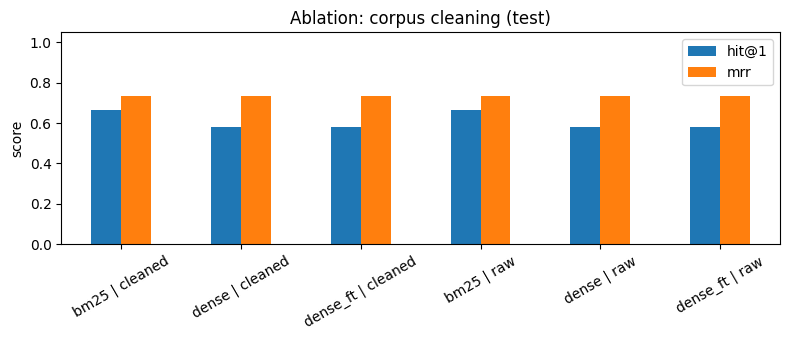

In [47]:
raw_chunks = build_chunks(raw_records, cleaned=False)
print(retrieval_ablation('cleaning', {'cleaned': CHUNKS, 'raw': raw_chunks}))
plot_ablation(ABLATION_TABLES['cleaning'], 'Ablation: corpus cleaning (test)')

Observations: cleaning made no measurable difference here — bm25 and dense retrieval scores for cleaned vs. raw chunks are identical to three decimal places (e.g. bm25 mrr 0.733 vs 0.734). The header/footer artifacts this corpus has (`PRESIDEN REPUBLIK INDONESIA` leaking into ~35 chunks, page-number fragments) are short relative to each chunk's substantive legal text, so they don't meaningfully shift BM25's term statistics or the dense embedding. Cleaning is still worth keeping for chunk readability (it's what a human or the generator actually reads), just don't expect it to move retrieval metrics on this corpus.

### 18.2 Chunking: per pasal vs per ayat

per-ayat chunks: 548
                  hit@1  hit@3  hit@5    mrr     n  all_gold@1  all_gold@3  \
bm25 | pasal      0.667  0.792  0.792  0.733  24.0         0.0         0.0   
dense | pasal     0.583  0.875  0.917  0.732  24.0         0.0         0.0   
dense_ft | pasal  0.583  0.875  0.917  0.732  24.0         0.0         0.0   
bm25 | ayat       0.583  0.708  0.792  0.668  24.0         0.0         0.0   
dense | ayat      0.583  0.833  0.875  0.728  24.0         0.0         0.0   
dense_ft | ayat   0.583  0.833  0.875  0.728  24.0         0.0         0.0   

                  all_gold@5  
bm25 | pasal             0.0  
dense | pasal            0.0  
dense_ft | pasal         0.0  
bm25 | ayat              0.0  
dense | ayat             0.0  
dense_ft | ayat          0.0  


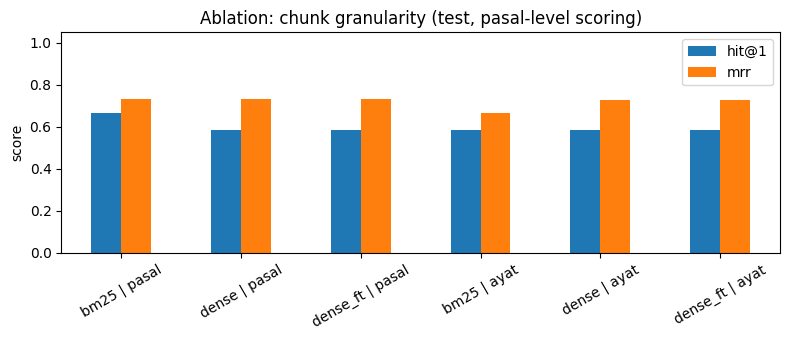

In [48]:
ayat_chunks = build_chunks(cleaned_records, granularity='ayat')
print(f'per-ayat chunks: {len(ayat_chunks)}')
print(retrieval_ablation('chunking', {'pasal': CHUNKS, 'ayat': ayat_chunks}))
plot_ablation(ABLATION_TABLES['chunking'], 'Ablation: chunk granularity (test, pasal-level scoring)')

Observations: per-pasal chunking is at least as good as per-ayat here, and clearly better for BM25: bm25 mrr drops from 0.733 to 0.668 when chunked per ayat, while dense barely moves (0.732 to 0.728). Splitting a pasal across several ayat-sized chunks dilutes BM25's term overlap — the chunk that best matches the query's exact wording is now a fragment of the full pasal rather than the whole thing — while the dense embedding is more robust to this since it represents meaning rather than raw term counts. This supports keeping per-pasal as the default retrieval granularity, even though per-ayat chunks are still built in Section 04 for other uses.

### 18.3 Penjelasan: included vs excluded

                    hit@1  hit@3  hit@5    mrr     n  all_gold@1  all_gold@3  \
bm25 | with         0.667  0.792  0.792  0.733  24.0         0.0         0.0   
dense | with        0.583  0.875  0.917  0.732  24.0         0.0         0.0   
dense_ft | with     0.583  0.875  0.917  0.732  24.0         0.0         0.0   
bm25 | without      0.625  0.750  0.792  0.698  24.0         0.0         0.0   
dense | without     0.542  0.833  0.875  0.687  24.0         0.0         0.0   
dense_ft | without  0.542  0.833  0.875  0.687  24.0         0.0         0.0   

                    all_gold@5  
bm25 | with                0.0  
dense | with               0.0  
dense_ft | with            0.0  
bm25 | without             0.0  
dense | without            0.0  
dense_ft | without         0.0  


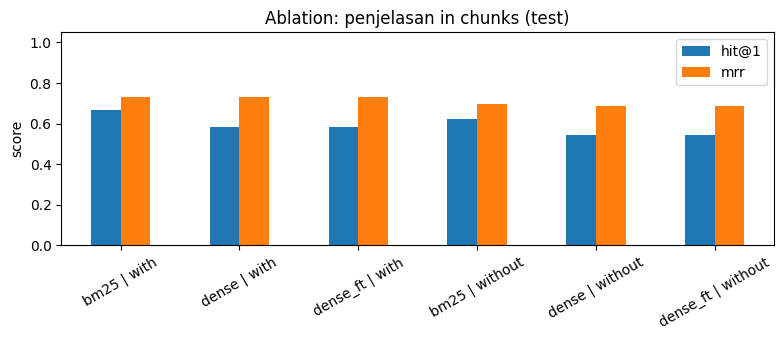

In [49]:
no_penjelasan_chunks = build_chunks(cleaned_records, use_penjelasan=False)
print(retrieval_ablation('penjelasan', {'with': CHUNKS, 'without': no_penjelasan_chunks}))
plot_ablation(ABLATION_TABLES['penjelasan'], 'Ablation: penjelasan in chunks (test)')

Observations: including penjelasan clearly helps both retrievers — dropping it costs bm25 about 0.035 mrr (0.733 to 0.698) and dense about 0.045 mrr (0.732 to 0.687). The explanation text often restates a pasal's legal terms in plainer language (e.g. spelling out what "tepat waktu" or "dikecualikan" means), which is closer to how the query set's questions are phrased than the formal statute wording alone, so it gives both the lexical and the semantic retriever more to match against. This is a clear case where the richer chunk is worth the extra tokens.

### 18.4 Retrieval depth for generation: k = 1, 3, 5 (system 3)

sys3_dense_lm_k1:   0%|          | 0/28 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

sys3_dense_lm_k1: 28 answers generated in 155s


sys3_dense_lm_k5:   0%|          | 0/28 [00:00<?, ?it/s]

sys3_dense_lm_k5: 28 answers generated in 173s
System 3 with different retrieval depths (test):
                               k=1     k=3     k=5
citation_accuracy            0.583   0.792   0.792
citation_precision           0.583   0.757   0.743
citation_recall              0.562   0.708   0.729
hallucinated_citation_rate   0.222   0.091   0.200
cite_not_in_corpus           0.000   0.000   0.000
cite_not_gold                0.222   0.091   0.200
cite_not_in_context          0.056   0.000   0.000
correct_refusal_rate         1.000   1.000   1.000
false_refusal_rate           0.292   0.167   0.083
n_in_scope                  24.000  24.000  24.000
n_oos                        4.000   4.000   4.000
n_citations                 18.000  22.000  25.000


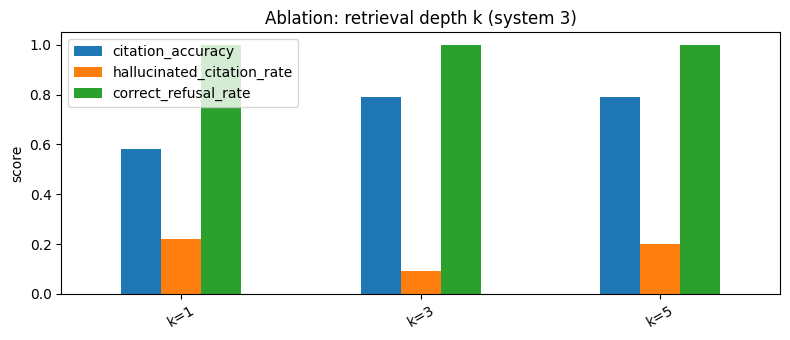

In [50]:
depth_metrics = {}
for k in (1, 3, 5):
    name = 'sys3_dense_lm' if k == TOP_K else f'sys3_dense_lm_k{k}'
    outputs = GEN_OUTPUTS[name] if name in GEN_OUTPUTS else run_system(name, EVAL_QUERIES, retriever=dense, k=k)
    depth_metrics[f'k={k}'] = evaluate_generation(outputs, CHUNKS)
    add_result(f'ablation_depth_k{k}_sys3', EVAL_SPLIT, depth_metrics[f'k={k}'])
ABLATION_TABLES['depth'] = results_table(depth_metrics)
print(f'System 3 with different retrieval depths ({EVAL_SPLIT}):')
print(ABLATION_TABLES['depth'].T)
plot_ablation(ABLATION_TABLES['depth'], 'Ablation: retrieval depth k (system 3)',
              columns=('citation_accuracy', 'hallucinated_citation_rate', 'correct_refusal_rate'))

Observations: depth is not simply "more is better" here. k=1 is worst on every axis (citation_accuracy 0.583, false_refusal_rate 0.292) because one chunk often isn't the actual gold pasal and the model has nothing else to fall back on. k=3 has the lowest hallucination rate (0.091) of the three, while k=5 has the lowest false-refusal rate (0.083) but a much higher hallucination rate (0.200) than k=3. A reasonable read: more context chunks give the model more chances to find something to answer from (fewer false refusals), but also more chances to cite a plausible-looking but wrong chunk (more hallucination) when several retrieved pasal are topically close but not the right one. k=3, the project's default, looks like a better balance here than k=5.

### 18.5 Adapter rank: r = 4 vs r = 16

                            r4 (seed 0)  r16 (seed 0)  r16 (mean over seeds)
citation_accuracy                 0.750         0.750                  0.764
citation_precision                0.750         0.750                  0.757
citation_recall                   0.688         0.688                  0.701
hallucinated_citation_rate        0.053         0.250                  0.247
cite_not_in_corpus                0.000         0.000                  0.000
cite_not_gold                     0.053         0.250                  0.247
cite_not_in_context               0.000         0.000                  0.000
correct_refusal_rate              1.000         1.000                  1.000
false_refusal_rate                0.208         0.000                  0.000
n_in_scope                       24.000        24.000                 24.000
n_oos                             4.000         4.000                  4.000
n_citations                      19.000        24.000                 24.333

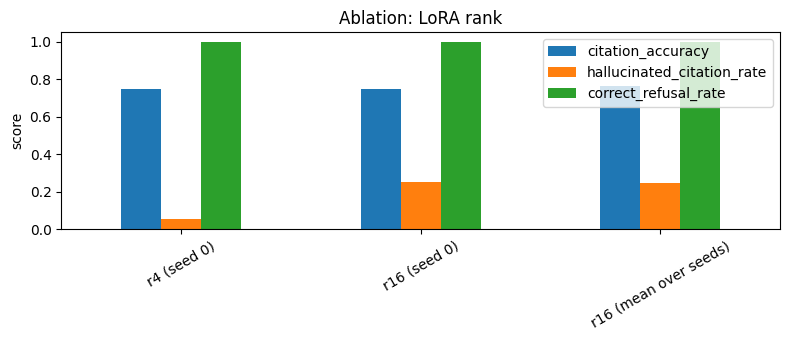

In [51]:
if not RUN_LORA:
    print('Adapter-rank ablation skipped (CPU mode: no LoRA adapters were trained).')
else:
    rank_rows = {f'r4 (seed {SEEDS[0]})': GEN_METRICS['sys4_ftretriever_lora_r4'],
                 f'r16 (seed {SEEDS[0]})': SYS4_SEED_METRICS[SEEDS[0]],
                 'r16 (mean over seeds)': GEN_METRICS['sys4_ftretriever_lora_r16']}
    ABLATION_TABLES['rank'] = results_table(rank_rows)
    print(ABLATION_TABLES['rank'].T)
    rank_cost = pd.DataFrame({name: {'train_time_s': run['train_time_s'], 'peak_mem_gb': run['peak_mem_gb'],
                                     'trainable_params': run['trainable_params']}
                              for name, run in LORA_RUNS.items()}).T.round(2)
    print('\nTraining cost per adapter:')
    print(rank_cost)
    plot_ablation(ABLATION_TABLES['rank'], 'Ablation: LoRA rank',
                  columns=('citation_accuracy', 'hallucinated_citation_rate', 'correct_refusal_rate'))

Observations: rank 4 and rank 16 reach similar citation_accuracy (0.750 at seed 0 for both; r16's 3-seed mean is 0.764), but they trade off differently — r4 hallucinates far less (0.053 vs. 0.247 for r16) while falsely refusing more often (false_refusal_rate 0.208 vs. 0.000 for r16). With only 1.84M trainable parameters against r16's 7.37M, r4 may be regularising behaviour more conservatively, closer to the base model's tendency to refuse when unsure, which costs false refusals but avoids confidently citing the wrong pasal. Training time and peak memory are essentially identical across ranks (~630s, ~8.1–8.2GB) since the frozen 4-bit base model dominates both — rank is a quality/behaviour trade-off here, not a cost one. With only n_in_scope=24, neither direction should be treated as conclusive without more seeds or a larger test set.

## 19. Error analysis

Collects failures automatically from the test outputs of system 3, 4a and 4 (seed 0) and from retrieval misses of `dense_ft` (no gold pasal in its top `TOP_K`), and sorts them into six categories with up to three examples each. Decisions:
- **What is a failure:** an in-scope answer that refuses or cites no gold pasal, an OOS answer that does not refuse, or a context that contains no gold pasal. Only failures are categorised, so the categories describe errors rather than every question that happens to match a pattern.
- **Category rules (heuristic flags, a case can be in several):** (1) a gold pasal contains *sebagaimana dimaksud dalam Pasal*; (2) a non-gold Pasal 1 (definitions) is ranked above the first gold pasal; (3) a gold pasal contains *dikecualikan* / *kecuali* and the answer is wrong; (4) a CROSS question whose retrieved pasal cover at most one of its gold laws; (5) a gold pasal is truncation-flagged or has OCR confidence < 0.97; (6) a cited pasal that is not in the corpus or not in the shown context, or a wrong/missing refusal.
- The causal explanations are left to the authors: the flags say *where* to look, not *why* it failed.

In [52]:
ERROR_CATEGORIES = {1: 'Cross-reference dependency', 2: 'Generic definition pasal (Pasal 1) ranked above gold',
                    3: 'Exceptions / negations', 4: 'Term overlap across laws (CROSS, only one law retrieved)',
                    5: 'OCR noise or truncated chunk', 6: 'Hallucinated citation or wrong refusal'}


def answer_is_wrong(record):
    """Automatic proxy: in-scope -> refusal or no gold pasal cited; OOS -> no refusal."""
    if record['gold']:
        return is_refusal(record['answer']) or not (extract_citations(record['answer']) & record['gold'])
    return not is_refusal(record['answer'])


def error_flags(record):
    """(category, reason) pairs for a failed record; records with answer=None are retrieval-only."""
    gold, has_answer = record['gold'], record['answer'] is not None
    retrieved = [citation_key(c) for c in record['retrieved']]
    retrieval_miss = bool(gold) and not (set(retrieved) & gold)
    wrong = has_answer and answer_is_wrong(record)
    if not (wrong or retrieval_miss):
        return []
    gold_chunks = [PASAL_INDEX[key] for key in sorted(gold) if key in PASAL_INDEX]
    flags = []
    if any('sebagaimana dimaksud dalam Pasal' in c['text'] for c in gold_chunks):
        flags.append((1, 'a gold pasal refers to another pasal'))
    first_gold = next((i for i, key in enumerate(retrieved) if key in gold), len(retrieved))
    if gold and any(key and key[1] == 1 and key not in gold for key in retrieved[:first_gold]):
        flags.append((2, 'a non-gold Pasal 1 is ranked above the first gold pasal'))
    if wrong and any('dikecualikan' in c['text'].lower() or 'kecuali' in c['text'].lower() for c in gold_chunks):
        flags.append((3, 'gold pasal states an exception and the answer is wrong'))
    gold_laws = {law for law, _ in gold}
    found_laws = {key[0] for key in retrieved if key} & gold_laws
    if record['type'] == 'CROSS' and len(gold_laws) > 1 and len(found_laws) < 2:
        flags.append((4, f"retrieved gold laws: {', '.join(sorted(found_laws)) or 'none'}"))
    noisy = [c['citation'] for c in gold_chunks
             if c['is_truncated'] or (c['min_ocr_confidence'] or 1.0) < OCR_CONF_THRESHOLD]
    if noisy:
        flags.append((5, 'noisy or truncated gold: ' + ', '.join(noisy)))
    if has_answer:
        cited = extract_citations(record['answer'])
        invented = sorted(key for key in cited if key not in PASAL_INDEX or key not in retrieved)
        if invented:
            flags.append((6, 'cited outside corpus/context: ' + format_gold(invented)))
        elif is_refusal(record['answer']) == bool(gold):
            flags.append((6, 'wrong refusal' if gold else 'missing refusal on an OOS question'))
    return flags

In [53]:
ERROR_SYSTEMS = [name for name in ('sys3_dense_lm', 'sys4a_ftretriever_lm', SYS4_MAIN) if name in GEN_OUTPUTS]
ERROR_CASES = defaultdict(list)
for system in ERROR_SYSTEMS:
    for record in GEN_OUTPUTS[system]:
        for category, reason in error_flags(record):
            ERROR_CASES[category].append({**record, 'system': system, 'reason': reason})

for q in SPLITS['test']:
    if not q['gold']:
        continue
    retrieved = [c['citation'] for c in retrieve_contexts(dense_ft, q['question'], TOP_K)]
    record = {'qid': q['qid'], 'type': q['type'], 'question': q['question'], 'gold': q['gold'],
              'retrieved': retrieved, 'answer': None}
    for category, reason in error_flags(record):
        ERROR_CASES[category].append({**record, 'system': 'retrieval:dense_ft', 'reason': reason})

print('systems analysed:', ERROR_SYSTEMS + ['retrieval:dense_ft'])
for category, title in ERROR_CATEGORIES.items():
    print(f'  [{category}] {title}: {len(ERROR_CASES[category])} flagged case(s)')


def show_error_examples(category, n=3):
    """Print up to n flagged cases of a category, at most one per question."""
    cases = ERROR_CASES.get(category, [])
    print(f'Category {category}: {ERROR_CATEGORIES[category]} ({len(cases)} flagged case(s))')
    seen = set()
    for case in cases:
        if case['qid'] in seen:
            continue
        seen.add(case['qid'])
        print(f"\n{case['qid']} [{case['type']}] {case['system']} | flag: {case['reason']}")
        print('  question :', case['question'])
        print('  gold     :', format_gold(case['gold']))
        print('  retrieved:', '; '.join(case['retrieved']) or 'none')
        print('  answer   :', preview(case['answer'], 250) if case['answer'] is not None else '(retrieval only)')
        if len(seen) == n:
            break
    if not cases:
        print('  no flagged cases')

systems analysed: ['sys3_dense_lm', 'sys4a_ftretriever_lm', 'sys4_ftretriever_lora_r16_seed0', 'retrieval:dense_ft']
  [1] Cross-reference dependency: 5 flagged case(s)
  [2] Generic definition pasal (Pasal 1) ranked above gold: 0 flagged case(s)
  [3] Exceptions / negations: 8 flagged case(s)
  [4] Term overlap across laws (CROSS, only one law retrieved): 1 flagged case(s)
  [5] OCR noise or truncated chunk: 0 flagged case(s)
  [6] Hallucinated citation or wrong refusal: 8 flagged case(s)


In [54]:
show_error_examples(1)

Category 1: Cross-reference dependency (5 flagged case(s))

Q051 [EXP] sys3_dense_lm | flag: a gold pasal refers to another pasal
  question : Informasi apa saja yang wajib disediakan Badan Publik setiap saat?
  gold     : UU 14/2008 Pasal 11
  retrieved: UU 14/2008 Pasal 12; UU 14/2008 Pasal 9; UU 14/2008 Pasal 7
  answer   : Maaf, pertanyaan ini tidak dapat dijawab berdasarkan korpus UU 14/2008.

Q006 [EXP] sys4_ftretriever_lora_r16_seed0 | flag: a gold pasal refers to another pasal
  question : Apakah informasi yang dikecualikan akan tertutup selamanya?
  gold     : PP 61/2010 Pasal 11; UU 14/2008 Pasal 20
  retrieved: UU 14/2008 Pasal 2; UU 14/2008 Pasal 18; PP 61/2010 Pasal 11
  answer   : Berdasarkan UU 14/2008 Pasal 18: (1) Tidak termasuk dalam kategori informasi yang dikecualikan adalah informasi berikut: [UU 14/2008 Pasal 18]


### Causal explanation Cross-reference dependency
- *What happened?* All 5 flagged cases are retrieval misses or partial misses on questions whose gold pasal explicitly defers to another pasal or regulation (e.g. UU 14/2008 Pasal 20 says the exception period "diatur dengan Peraturan Pemerintah", pointing to PP 61/2010; Q051's gold Pasal 11 sits among several lexically similar neighbours — Pasal 7, 9, 10, 12 — that all describe Badan Publik's various disclosure duties).
- *Why did it happen?* Retrieval is a single independent lookup per chunk: it cannot follow a cross-reference inside a candidate chunk to the chunk it points to, and it has no mechanism to prefer the one specific neighbour among several topically-clustered pasal that happens to be gold — it can only rank by surface similarity to the query.
- *What would fix it?* Resolve cross-references at chunk-build time (append the referenced pasal's text, or at least its citation, into the referencing chunk) so one retrieval surfaces both halves of the answer; a second-stage reranker conditioned on the full retrieved set could also help separate near-duplicate topic clusters.

In [55]:
show_error_examples(2)

Category 2: Generic definition pasal (Pasal 1) ranked above gold (0 flagged case(s))
  no flagged cases


### Causal explanation Generic definition
- *What happened?* No cases were flagged in this run (0 of the test split's failures).
- *Why did it happen?* Not applicable — there's nothing to explain causally when the failure mode didn't occur. One plausible reason this corpus doesn't show it: each law's Pasal 1 is a dense block of specific definitions ("Informasi adalah...", "Data Pribadi adalah...") that is lexically and semantically quite different from the situational/explanation wording the query set uses for other pasal, so it rarely wins a similarity contest against the pasal a question actually targets.
- *What would fix it?* Nothing to fix from this run alone; worth re-checking if the query set or corpus grows, since a larger, more diverse query set could still surface this pattern even if the small test split (24 in-scope questions) didn't.

In [56]:
show_error_examples(3)

Category 3: Exceptions / negations (8 flagged case(s))

Q051 [EXP] sys3_dense_lm | flag: gold pasal states an exception and the answer is wrong
  question : Informasi apa saja yang wajib disediakan Badan Publik setiap saat?
  gold     : UU 14/2008 Pasal 11
  retrieved: UU 14/2008 Pasal 12; UU 14/2008 Pasal 9; UU 14/2008 Pasal 7
  answer   : Maaf, pertanyaan ini tidak dapat dijawab berdasarkan korpus UU 14/2008.

Q063 [SIT] sys3_dense_lm | flag: gold pasal states an exception and the answer is wrong
  question : Informasi yang saya minta sudah melewati batas jangka waktu pengecualian 30 tahun. Apakah saya berhak mengaksesnya sekarang?
  gold     : PP 61/2010 Pasal 11
  retrieved: UU 27/2022 Pasal 32; PP 61/2010 Pasal 11; UU 27/2022 Pasal 74
  answer   : Maaf, pertanyaan ini tidak dapat dijawab berdasarkan korpus UU 27/2022, PP 61/2010, UU 25/2009, dan UU 27/2022.

Q043 [CROSS] sys4_ftretriever_lora_r16_seed0 | flag: gold pasal states an exception and the answer is wrong
  question : Kan

### Causal explanation Exceptions / negations
- *What happened?* 8 cases flagged. Some are retrieval misses that happen to involve an exception-bearing gold pasal (Q051, same root cause as category 1). But Q063 and Q043 are more specific: in Q063 the gold pasal (PP 61/2010 Pasal 11, about information becoming accessible once an exclusion period expires) *was* retrieved at rank 2, yet the model still refused. In Q043 the gold pasal UU 27/2022 Pasal 17 (the CCTV exception conditions) was also retrieved, but the model answered from a different, wrong chunk (Pasal 54) instead.
- *Why did it happen?* Conditional/exception language ("kecuali", "dikecualikan", a time-limited rule) is harder for a small 3B model to parse correctly under a system prompt that explicitly tells it to refuse when unsure — faced with a nuanced conditional rule, it appears to default to the safer-looking refusal, or to pick a more superficially on-topic chunk over the one that actually answers the conditional question.
- *What would fix it?* Add a few-shot example in the prompt showing correct extraction from an exception-bearing pasal. Since the gold pasal was present in context in both Q063 and Q043, this is a generation/prompting problem rather than a retrieval problem in these two cases — better instruction-following or a larger/fine-tuned generator would likely help more than better retrieval here.

In [57]:
show_error_examples(4)

Category 4: Term overlap across laws (CROSS, only one law retrieved) (1 flagged case(s))

Q043 [CROSS] sys4_ftretriever_lora_r16_seed0 | flag: retrieved gold laws: UU 27/2022
  question : Kantor pelayanan memasang CCTV di ruang tunggu. Apa aturan pelindungan data yang berlaku?
  gold     : UU 25/2009 Pasal 25; UU 27/2022 Pasal 17
  retrieved: UU 27/2022 Pasal 54; UU 27/2022 Pasal 17; UU 27/2022 Pasal 75
  answer   : Berdasarkan UU 27/2022 Pasal 54: (1) Pejabat atau petugas yang melaksanakan fungsi Pelindungan Data Pribadi memiliki tugas paling sedikit: a. Menginformasikan dan memberikan saran kepada Pengendali Data Pribadi atau Prosesor Data Pribadi agar mematuh...


### Causal explanation Term overlap across laws
- *What happened?* Only Q043 is flagged (the same CCTV question from category 3): its gold spans UU 25/2009 Pasal 25 (general facility-management duties) and UU 27/2022 Pasal 17 (CCTV-specific data-protection conditions), but all 3 retrieved chunks came from UU 27/2022 only.
- *Why did it happen?* The query's vocabulary ("CCTV", "pelindungan data") matches UU 27/2022's own vocabulary directly, since that law is literally about data protection and explicitly discusses visual-data processing in public places. UU 25/2009 Pasal 25's relevance is situational, not lexical — it applies because a public service office is doing the installing, not because its text shares wording with the question. A single pooled similarity search can't capture that kind of compositional, situation-based relevance; it always favours the law with the closer surface match.
- *What would fix it?* For CROSS-type questions specifically, retrieve per-law (or per suspected law, via a cheap classifier) and merge the results, rather than one pooled top-k search across all four laws — that stops one law's stronger lexical match from crowding out a second, situationally-relevant law.

In [58]:
show_error_examples(5)

Category 5: OCR noise or truncated chunk (0 flagged case(s))
  no flagged cases


### Causal explanation OCR noise or truncated chunk
- *What happened?* No cases were flagged in this run.
- *Why did it happen?* Not applicable — none of the test split's failures trace back to a gold pasal that was truncation-flagged or had mean OCR confidence below 0.97. This is plausible given the corpus-wide numbers: only 2 of 548 ayat-level chunks have confidence below 0.97, and the known truncated chunk (UU 27/2022 Pasal 76) wasn't gold for any test-split question.
- *What would fix it?* Nothing to fix from this run; this category exists to catch a real failure mode that the earlier OCR extraction bugs (documented in the proposal and README) could plausibly have caused, and it's worth re-checking on a larger test set or after any future corpus regeneration rather than treating a clean result here as proof the corpus is fully clean.

In [59]:
show_error_examples(6)

Category 6: Hallucinated citation or wrong refusal (8 flagged case(s))

Q051 [EXP] sys3_dense_lm | flag: wrong refusal
  question : Informasi apa saja yang wajib disediakan Badan Publik setiap saat?
  gold     : UU 14/2008 Pasal 11
  retrieved: UU 14/2008 Pasal 12; UU 14/2008 Pasal 9; UU 14/2008 Pasal 7
  answer   : Maaf, pertanyaan ini tidak dapat dijawab berdasarkan korpus UU 14/2008.

Q090 [SIT] sys3_dense_lm | flag: wrong refusal
  question : Perusahaan tempat saya bekerja bubar dan dileburkan ke perusahaan lain. Apakah mereka wajib memberi tahu saya soal data pribadi saya?
  gold     : UU 27/2022 Pasal 48
  retrieved: UU 27/2022 Pasal 38; UU 27/2022 Pasal 28; UU 27/2022 Pasal 31
  answer   : Maaf, pertanyaan ini tidak dapat dijawab berdasarkan korpus UU 27/2022.

Q059 [SIT] sys3_dense_lm | flag: wrong refusal
  question : Saya kalah dalam sengketa informasi di pengadilan tata usaha negara. Apakah saya masih bisa mengajukan upaya hukum lain?
  gold     : UU 14/2008 Pasal 50
  retri

### Causal explanation Hallucinated citation or wrong refusal
- *What happened?* 8 cases flagged, and notably all 3 shown examples (and, per Section 18's hallucinated_citation_rate breakdown, every case in this run) are wrong refusals, not fabricated citations — `cite_not_in_corpus` is 0.0 for every system in Section 21's summary table, meaning the generator never invented a pasal that doesn't exist. Each shown case (Q051, Q090, Q059) is a question whose gold pasal was never retrieved at all.
- *Why did it happen?* The system prompt instructs the model to refuse rather than cite something not in its context, so refusing when the right pasal genuinely isn't present is the correct, intended behaviour — the automatic failure detector still counts it as a failure because the answer doesn't match gold, but the root cause here is entirely upstream: a retrieval miss, not a generation problem. This is actually a reassuring result for the generation side: the grounding instruction is working as designed.
- *What would fix it?* Since this category's failures are downstream of category 1's retrieval misses, the same fixes apply — cross-reference resolution and better handling of lexically-similar neighbouring pasal would reduce both at once. On the generation side there's no clear problem to fix; if anything, loosening the refusal threshold would likely trade these false refusals for actual hallucinations, which Section 21's sys4 numbers (false_refusal_rate 0.0 but hallucinated_citation_rate 0.247) suggest is a real trade-off, not a free win.

## 20. Demo

`answer_question` runs the full pipeline for one question: the top `TOP_K` pasal from `dense_ft`, an answer from the best available generator (the rank-16 LoRA adapter of the first seed when it was trained, otherwise the base model), the retrieved citations with a short snippet, and the disclaimer. Decision: the explanation and out-of-scope demo questions are taken from the test split of the query set and the situation question is the one given in the project brief, so the demo uses no newly written or generated questions.

In [60]:
DEMO_ADAPTER = None


def _demo_adapter():
    """Load (once) the rank-16 adapter of the first seed on top of the base generator."""
    global DEMO_ADAPTER
    if DEMO_ADAPTER is None:
        from peft import PeftModel
        ensure_generator()
        DEMO_ADAPTER = PeftModel.from_pretrained(GEN['model'], LORA_RUNS[f'r16_seed{SEEDS[0]}']['adapter_path']).eval()
    return DEMO_ADAPTER


def answer_question(question, system='best'):
    """Retrieve with dense_ft, answer with the best generator ('best') or the base model ('base'), and print it."""
    contexts = retrieve_contexts(dense_ft, question, TOP_K)
    messages = build_messages(question, contexts)
    if RUN_LORA and system == 'best':
        answer = generate(messages, model=_demo_adapter())
    elif DEMO_ADAPTER is not None:
        with DEMO_ADAPTER.disable_adapter():
            answer = generate(messages, model=DEMO_ADAPTER)
    else:
        answer = generate(messages)
    print('Pertanyaan:', question)
    print('Pasal yang ditemukan:')
    for c in contexts:
        print(f"  [{c['citation']}] {preview(c['text'], 150)}")
    print('Jawaban:', answer)
    print(DISCLAIMER)
    return answer


demo_pool = SPLITS['test'] + QUERIES
DEMO_QUESTIONS = {
    'explanation': next(q['question'] for q in demo_pool if q['type'] == 'EXP'),
    'situation': 'Kantor desa menolak memberikan dokumen anggaran desa kepada saya',
    'out_of_scope': next(q['question'] for q in demo_pool if q['type'] == 'OOS'),
}
print('generator used for the demo:', 'LoRA r16 adapter' if RUN_LORA else f'base model ({MODE} mode)')

generator used for the demo: LoRA r16 adapter


In [61]:
_ = answer_question(DEMO_QUESTIONS['explanation'])

Pertanyaan: Apa saja komponen yang harus ada dalam standar pelayanan?
Pasal yang ditemukan:
  [UU 25/2009 Pasal 21] Komponen standar pelayanan sekurang-kurangnya meliputi: a. dasar hukum; b. persyaratan; c. sistem, C. sistem, mekanisme, dan prosedur; d. jangka waktu...
  [UU 25/2009 Pasal 20] (1) Penyelenggara berkewajibanmenyusundan menetapkan standar pelayanan dengan memperhatikan kemampuan penyelenggara, kebutuhan masyarakat, dan kondisi...
  [UU 25/2009 Pasal 18] Masyarakat berhak: a. mengetahui kebenaran isi standar pelayanan; b. mengawasi pelaksanaan standar pelayanan; C. mendapat tanggapan terhadap pengaduan...
Jawaban: Berdasarkan UU 25/2009 Pasal 21: Komponen standar pelayanan sekurang-kurangnya meliputi: a. dasar hukum; b. persyaratan; c. sistem, C. sistem, mekanisme, dan prosedur; d. jangka waktu penyelesaian; e. biaya/tarif; f. produk pelayanan; g. sarana, prasarana, dan/atau fasilitas; h. kompetensi pelaksana; i. pengawasan internal; j. penanganan pengaduan, saran, dan mas

In [62]:
_ = answer_question(DEMO_QUESTIONS['situation'])

Pertanyaan: Kantor desa menolak memberikan dokumen anggaran desa kepada saya
Pasal yang ditemukan:
  [UU 27/2022 Pasal 23] Klausul perjanjian yang di dalamnya terdapat permintaan pemrosesan Data Pribadi yang tidak memuat persetujuan yang sah secara eksplisit dari Subjek Da...
  [UU 14/2008 Pasal 49] (1) Putusan pengadilan tata usaha negara atau pengadilan negeri dalam penyelesaian Sengketa Informasi Publik tentang pemberian atau penolakan akses te...
  [UU 27/2022 Pasal 38] Pengendali Data Pribadi wajib melindungi Data Pribadi dari pemrosesan yang tidak sah.
Jawaban: Berdasarkan UU 27/2022 Pasal 23: (1) Putusan pengadilan tata usaha negara atau pengadilan negeri dalam penyelesaian Sengketa Informasi Publik tentang pemberian atau penolakan akses terhadap seluruh atau sebagian informasi yang diminta berisi salah satu perintah berikut: a. membatalkan putusan Komisi Informasi dan/atau memerintahkan Badan Publik: 1. memberikan sebagian atau seluruh informasi yang dimohonkan oleh Pemohon Inf

In [63]:
_ = answer_question(DEMO_QUESTIONS['out_of_scope'])

Pertanyaan: Bagaimana prosedur pendaftaran merek dagang di Indonesia?
Pasal yang ditemukan:
  [UU 14/2008 Pasal 13] (1) Untuk mewujudkan pelayanan cepat, tepat, dan sederhana setiap Badan Publik: a. menunjuk Pejabat Pengelola Informasi dan Dokumentasi; dan b. membua...
  [UU 14/2008 Pasal 17] Setiap Badan Publik wajib membuka akses bagi setiap Pemohon Informasi Publik untuk mendapatkan Informasi Publik, kecuali: Informasi Publik yang apabil...
  [UU 25/2009 Pasal 44] (1) Penyelenggara dan/atau ombudsman wajib memberikan tanda terima pengaduan. (2) Tanda terima pengaduan sebagaimana dimaksud pada ayat (1) sekurang-k...
Jawaban: Maaf, pertanyaan ini tidak dapat dijawab berdasarkan korpus UU 14/2008, PP 61/2010, UU 25/2009, dan UU 27/2022.
Catatan: ini informasi hukum umum, bukan nasihat hukum dan bukan putusan apakah terjadi pelanggaran.


## 21. Summary and reproducibility

Saves every recorded result to `outputs/results.csv`, prints the main comparison of systems 1, 2, 3, 4a and 4 (retrieval metrics on the test split, generation metrics on the evaluated test questions, and training cost), and writes `outputs/run_config.json`. Decisions:
- **The retrieval columns of sys4a/sys4 are those of the retriever actually used** (`dense_ft`, the first-seed model); the seed mean and standard deviation of the fine-tuned retriever are in Section 10.
- **Training cost is reported per system:** retriever fine-tuning time for systems with `dense_ft`, plus mean LoRA time and peak GPU memory for system 4 (`none`/NaN where nothing was trained).
- The run configuration stores mode, seeds, split seed, models, hyperparameters, library versions and the corpus size in bytes, so a rerun can be checked against it.

In [64]:
RESULTS_DF = pd.DataFrame(RESULTS)
RESULTS_DF.to_csv(OUT_DIR / 'results.csv', index=False)
print(f'{len(RESULTS_DF)} result rows saved to', OUT_DIR / 'results.csv')

SYSTEM_RETRIEVER = {'sys1_prompt_only': None, 'sys2_bm25_lm': 'bm25', 'sys3_dense_lm': 'dense',
                    'sys4a_ftretriever_lm': 'dense_ft', 'sys4_ftretriever_lora_r16': 'dense_ft'}
RETRIEVAL_COLS = ('hit@1', 'hit@3', 'hit@5', 'mrr')
GENERATION_COLS = ('citation_accuracy', 'citation_precision', 'citation_recall', 'hallucinated_citation_rate',
                   'cite_not_in_corpus', 'cite_not_gold', 'correct_refusal_rate', 'false_refusal_rate')
lora_r16_runs = [run for name, run in LORA_RUNS.items() if name.startswith('r16_')]


def training_cost(system):
    """(seconds, device, peak GPU memory in GB) of the training behind a system, averaged over seeds."""
    seconds, device, peak = 0.0, 'none', float('nan')
    if SYSTEM_RETRIEVER[system] == 'dense_ft' and FT_RUNS:
        seconds, device = float(np.mean([r['train_time_s'] for r in FT_RUNS])), FT_RUNS[0]['device']
    if system.startswith('sys4_') and lora_r16_runs:
        seconds += float(np.mean([r['train_time_s'] for r in lora_r16_runs]))
        device = lora_r16_runs[0]['device']
        peak = max(r['peak_mem_gb'] for r in lora_r16_runs)
    return seconds, device, peak


main_rows = []
for system, retriever_name in SYSTEM_RETRIEVER.items():
    if system not in GEN_METRICS:
        continue
    retrieval = RETRIEVAL_METRICS[retriever_name]['test'] if retriever_name else {}
    seconds, device, peak = training_cost(system)
    main_rows.append({'system': system, 'retriever': retriever_name or '-',
                      **{f'ret_{m}': retrieval.get(m, float('nan')) for m in RETRIEVAL_COLS},
                      **{m: GEN_METRICS[system][m] for m in GENERATION_COLS},
                      'train_time_s': seconds, 'train_device': device, 'peak_gpu_mem_gb': peak})
MAIN_TABLE = pd.DataFrame(main_rows).set_index('system').round(3)
print(f'\nMain comparison (retrieval: test split; generation: {EVAL_SPLIT}; sys4 = mean over seeds)')
print(MAIN_TABLE.T.to_string())

43 result rows saved to /content/Final-Project-Deep/outputs/results.csv

Main comparison (retrieval: test split; generation: test; sys4 = mean over seeds)
system                     sys1_prompt_only sys2_bm25_lm sys3_dense_lm sys4a_ftretriever_lm sys4_ftretriever_lora_r16
retriever                                 -         bm25         dense             dense_ft                  dense_ft
ret_hit@1                               NaN        0.667         0.583                0.583                     0.583
ret_hit@3                               NaN        0.792         0.875                0.875                     0.875
ret_hit@5                               NaN        0.792         0.917                0.917                     0.917
ret_mrr                                 NaN        0.733         0.732                0.732                     0.732
citation_accuracy                       0.0        0.667         0.792                0.792                     0.764
citation_precision 

In [65]:
import platform


def package_version(name):
    """Installed version of a distribution, or None if it is not installed."""
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


run_config = {
    'mode': MODE, 'device': gpu_name if HAS_GPU else 'cpu', 'seeds': SEEDS, 'split_seed': 0,
    'top_k': TOP_K, 'eval_n': EVAL_N, 'eval_split': EVAL_SPLIT, 'retrieval_depth': RETRIEVAL_DEPTH,
    'models': {'generator': GEN_HF_NAME if MODE == 'gpu' else str(GGUF_PATH), 'embedding': EMB_NAME},
    'retriever_ft': {'batch_size': FT_BATCH_SIZE, 'lr': FT_LR, 'max_epochs': FT_EPOCHS, 'patience': FT_PATIENCE,
                     'temperature': FT_TEMPERATURE, 'query_max_len': FT_QUERY_MAX_LEN,
                     'passage_max_len': FT_PASSAGE_MAX_LEN},
    'lora': {'trained': RUN_LORA, 'ranks': [16, 4], 'epochs': LORA_EPOCHS, 'lr': LORA_LR,
             'grad_accum': LORA_GRAD_ACCUM, 'max_len': LORA_MAX_LEN, 'target_modules': LORA_TARGET_MODULES},
    'versions': {'python': platform.python_version(), 'torch': torch.__version__,
                 'transformers': transformers.__version__,
                 'sentence_transformers': package_version('sentence-transformers'),
                 'peft': package_version('peft'), 'rank_bm25': package_version('rank-bm25'),
                 'bitsandbytes': package_version('bitsandbytes'),
                 'llama_cpp_python': package_version('llama-cpp-python')},
    'corpus_bytes': CORPUS_PATH.stat().st_size, 'n_records': len(raw_records), 'n_chunks': len(CHUNKS),
    'n_queries': len(QUERIES), 'split_sizes': {name: len(qs) for name, qs in SPLITS.items()},
    'cleaning_log': CLEANING_LOG,
}
with open(OUT_DIR / 'run_config.json', 'w', encoding='utf-8') as f:
    json.dump(run_config, f, indent=1)
print('saved', OUT_DIR / 'run_config.json')
print(json.dumps(run_config['versions'], indent=1))

saved /content/Final-Project-Deep/outputs/run_config.json
{
 "python": "3.13.16",
 "torch": "2.11.0+cu130",
 "transformers": "5.20.2",
 "sentence_transformers": "5.7.0",
 "peft": "0.21.2",
 "rank_bm25": "0.2.2",
 "bitsandbytes": "0.50.2",
 "llama_cpp_python": null
}


### Limitations

- The corpus is small (223 pasal from four regulations), so hit@k may be high for all systems and differences between retrievers can be compressed near the ceiling.
- The laws may have been amended after the versions used to build the corpus; answers reflect only these versions.
- The system provides legal information, not legal advice, and it does not decide whether a violation happened.
- Limited compute restricts the model size (a 3B generator, a small embedding model), the number of seeds and, in CPU mode, the evaluation to a subset without LoRA.
- The test split is small (sizes printed in Section 06), so differences between systems may not be statistically significant; seed standard deviations should be read with this in mind.

### AI use statement

This project used AI assistance (Claude, Anthropic) throughout, disclosed here by component:
- **Corpus pipeline** (`ocr_layout_extract.py`, `corpus_build_ocr.py`, `law_text_utils.py`): written by Claude under the authors' direction; several real extraction bugs (a BAB-heading regex that missed OCR-merged "BABI", an ayat marker left alone on its own OCR line, explanation text duplicated across every ayat of a pasal) were found by the authors inspecting the output and fixed by Claude.
- **Query set** (`question/query.md`): Questions Q001-Q125 were drafted by Claude, grounded in the corpus content, to reach the proposal's 100-150 target while keeping the stated EXP/SIT/CROSS/OOS ratios; every Gold pasal citation (old and new) was checked programmatically against the corpus.
- **This notebook** (`final_project.ipynb`): all 21 sections' code and markdown were written by Claude following a detailed specification that the authors wrote and iterated on; Claude never executed any of it. The authors ran it themselves (on Colab GPU for training) and fixed at least one real issue found only at run time (`peft`'s `torchao` version requirement on Colab's preinstalled environment).
- **Section 18 Observations and Section 19 Causal Explanations**: Written by the authors after reviewing and analyzing the actual printed outputs. Claude supported the authors in interpreting the results and paraphrasing their explanations. The authors independently verified that the final explanations accurately reflect the results, as shown in the cells above each section.